# Importing Dependencies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import datetime
import math
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from pmdarima import auto_arima
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from keras.preprocessing.sequence import TimeseriesGenerator
from keras.models import Sequential
from keras.layers import Dense, LSTM

import warnings
warnings.filterwarnings("ignore")

# Data Exploration

In [2]:
df = pd.DataFrame(pd.read_excel("Vegetable Price Prediction.xlsx", index_col="Date", parse_dates= True))
print("Shape of Data: ", df.shape)
df.head()

Shape of Data:  (1201, 8)


,Potato,Onion,Peas,Tomato,Carrot,Garlic,Ginger,Green Chilli
Date,,,,,,,,
2023-03-05,38.0,125.0,95.0,38.0,55.0,270.0,520.0,70.0
2023-03-04,33.0,110.0,90.0,30.0,45.0,270.0,500.0,70.0
2023-03-03,28.0,103.0,95.0,35.0,50.0,260.0,520.0,80.0
2023-03-02,30.0,110.0,100.0,38.0,40.0,250.0,500.0,70.0
2023-03-01,30.0,105.0,140.0,33.0,45.0,230.0,500.0,80.0


In [3]:
df.columns

Index(['Potato', 'Onion', 'Peas', 'Tomato', 'Carrot', 'Garlic', 'Ginger',
       'Green Chilli'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1201 entries, 2023-03-05 to 2019-11-21
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Potato        1042 non-null   float64
 1   Onion         1106 non-null   float64
 2   Peas          642 non-null    float64
 3   Tomato        1105 non-null   float64
 4   Carrot        975 non-null    float64
 5   Garlic        1108 non-null   float64
 6   Ginger        1101 non-null   float64
 7   Green Chilli  1108 non-null   float64
dtypes: float64(8)
memory usage: 84.4 KB


In [5]:
df.describe()

,Potato,Onion,Peas,Tomato,Carrot,Garlic,Ginger,Green Chilli
count,1042.000000,1106.000000,642.000000,1105.000000,975.000000,1108.000000,1101.000000,1108.000000
mean,33.380998,53.171790,122.987539,69.020814,58.696410,186.730144,280.210718,94.154332
std,7.624959,41.119904,64.895138,45.120878,28.767105,67.668037,95.235952,40.894831
min,18.000000,10.000000,25.000000,10.000000,20.000000,20.000000,140.000000,30.000000
25%,28.000000,30.000000,70.000000,33.000000,35.000000,140.000000,230.000000,60.000000
50%,32.000000,38.000000,100.000000,60.000000,50.000000,170.000000,250.000000,80.000000
75%,38.000000,58.000000,180.000000,90.000000,80.000000,250.000000,310.000000,120.000000
max,70.000000,192.000000,340.000000,260.000000,270.000000,430.000000,700.000000,300.000000


# Detecting Outliers

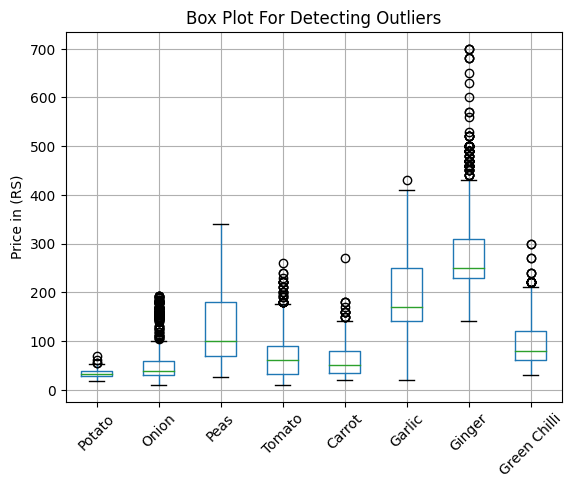

In [3]:
df.boxplot()
plt.ylabel("Price in (RS)")
plt.xticks(rotation=45)
plt.title("Box Plot For Detecting Outliers")
plt.show()

## Handling Outliers

In [3]:
# findoutliers will list the number of outliers in each column and handle them by replacing the outliers with the
# lower or upper limit of the quantile range

def findoutliers(column):
    outliers=[]
    Q1= column.quantile(.25)
    Q3= column.quantile(.75)
    IQR= Q3-Q1
    lower_limit= Q1-(1.5*IQR)
    upper_limit= Q3+(1.5*IQR)
        
    for i in range (len(column)):
        if (column[i]>upper_limit):
            outliers.append(column[i])
            column[i]=upper_limit
            
        elif (column[i]<lower_limit):
            outliers.append(column[i])
            column[i]=lower_limit
    
    return outliers

for i in df.columns:
    print("Number of outliers in "+i+" are:", len(findoutliers(df[i])))

Number of outliers in Potato are: 4
Number of outliers in Onion are: 133
Number of outliers in Peas are: 0
Number of outliers in Tomato are: 34
Number of outliers in Carrot are: 15
Number of outliers in Garlic are: 1
Number of outliers in Ginger are: 102
Number of outliers in Green Chilli are: 19


# Detecting Data Skewness

In [4]:
# Skewed data---> null values will be replaced with median/mode

for i in df.columns:
    skewness = df[i].skew()
    
    if (skewness==0):
        print(i+" is Skewed with a value of= "+skewness)
    elif (skewness<0):
        print(i+" is Negatively Skewed with a value of= "+str(skewness))
    else:
        print(i+" is Positively Skewed with a value of= "+str(skewness))

Potato is Positively Skewed with a value of= 0.5042031377227894
Onion is Positively Skewed with a value of= 1.0837907904754642
Peas is Positively Skewed with a value of= 0.9897568223992387
Tomato is Positively Skewed with a value of= 0.8515765454645045
Carrot is Positively Skewed with a value of= 1.0518288160187883
Garlic is Positively Skewed with a value of= 0.6106047949571414
Ginger is Positively Skewed with a value of= 0.5985542375148428
Green Chilli is Positively Skewed with a value of= 0.9554966281663199


# Detecting and Handling Null Values

In [9]:
# Check for Null Values
df.isnull().sum()

Potato          159
Onion            95
Peas            559
Tomato           96
Carrot          226
Garlic           93
Ginger          100
Green Chilli     93
dtype: int64

In [5]:
# Replacing null values in each column with the median value
for i in df.columns:
    df[i] = df[i].fillna(df[i].median())

# Detecting Stationarity of Data

In [6]:
# The data needs to be stationary to apply Time Series models 
def adfuller_test(datacol):
    df_test= adfuller(datacol, autolag="AIC")
    
    if (df_test[1]<=0.05):
        return "Stationary Data"
    else:
        return "Non-Stationary Data"

for i in df.columns:
    res= adfuller_test(df[i])
    print(i+": "+res)

Potato: Stationary Data
Onion: Non-Stationary Data
Peas: Stationary Data
Tomato: Stationary Data
Carrot: Non-Stationary Data
Garlic: Stationary Data
Ginger: Stationary Data
Green Chilli: Stationary Data


# Data Visualization

### Price Variance of Vegetables Over Time

<Figure size 1000x600 with 0 Axes>

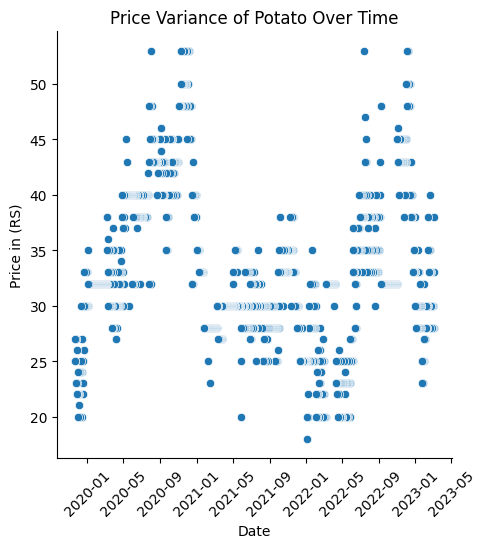

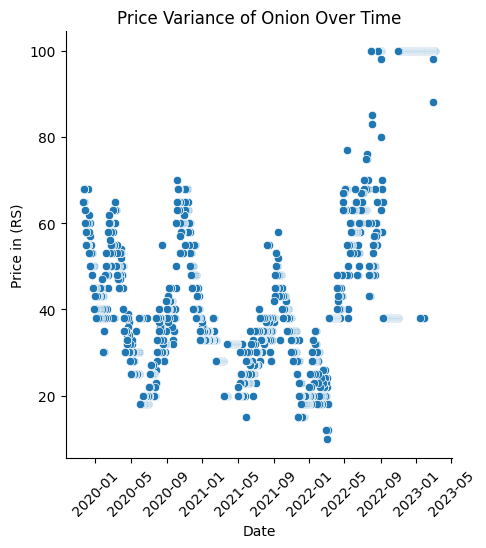

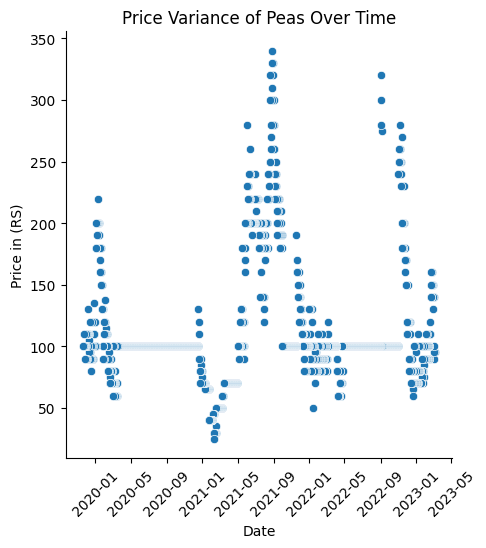

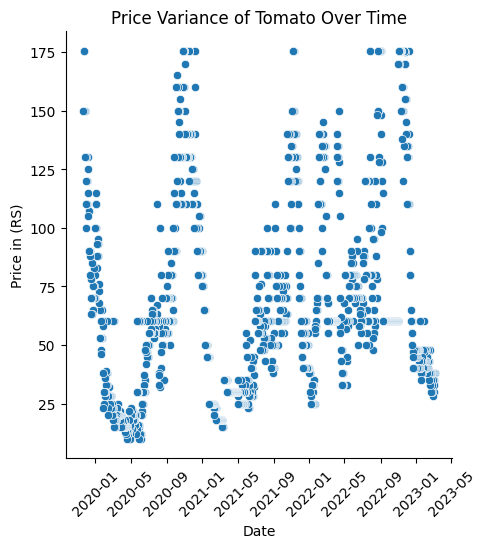

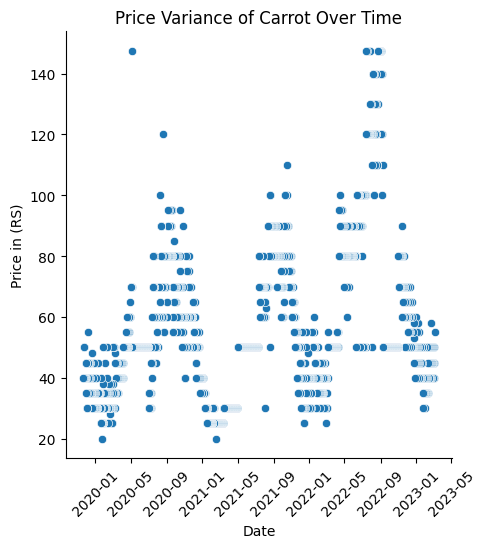

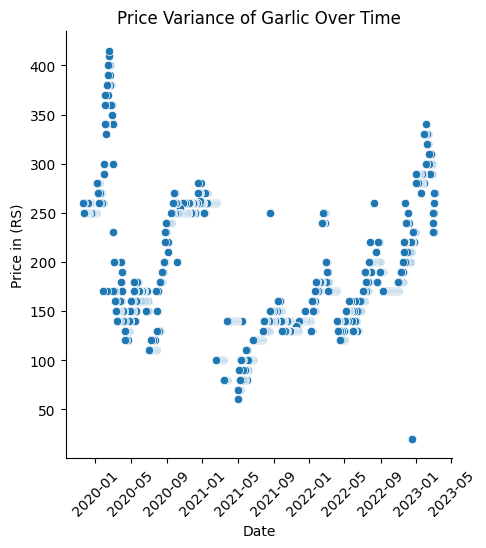

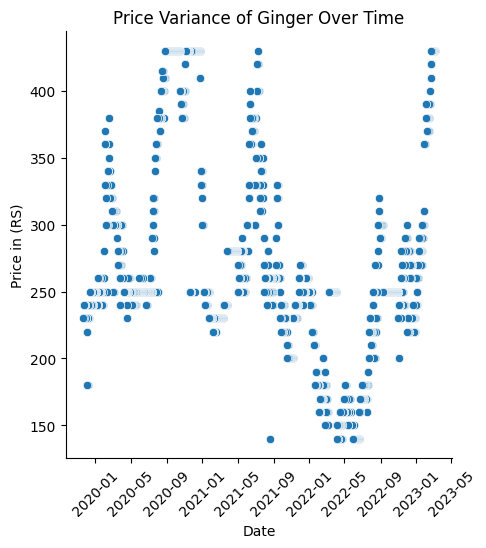

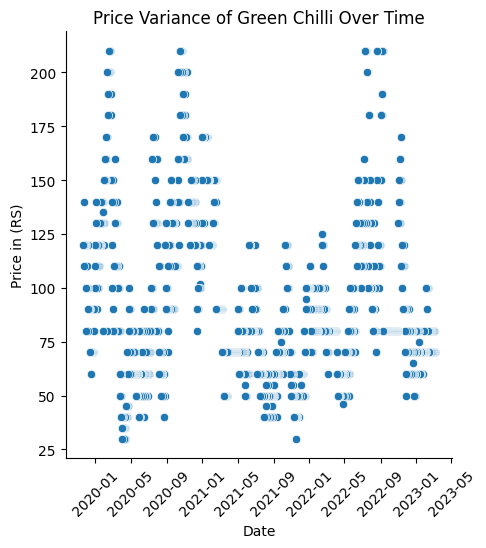

In [12]:
# Scatter Plot
plt.figure(figsize=(10,6))

for col in df.columns:
    sns.relplot(data=df,x=df.index,y=col)
    plt.xticks(rotation=45)
    plt.ylabel("Price in (RS)")
    plt.title("Price Variance of "+col+ " Over Time")
    plt.show()

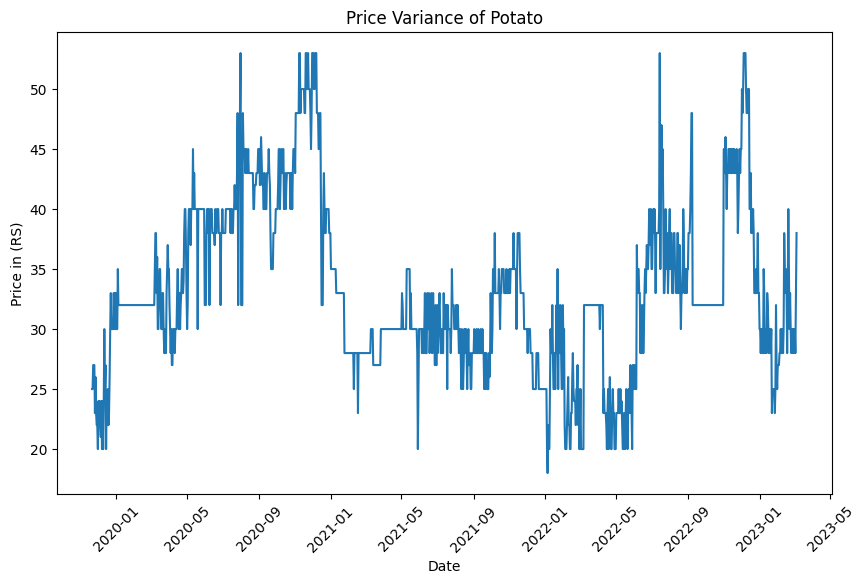

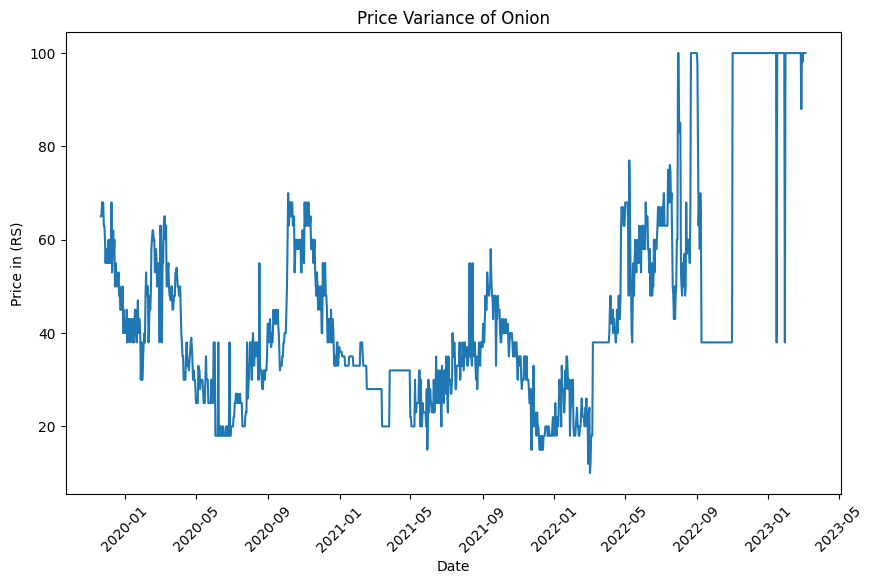

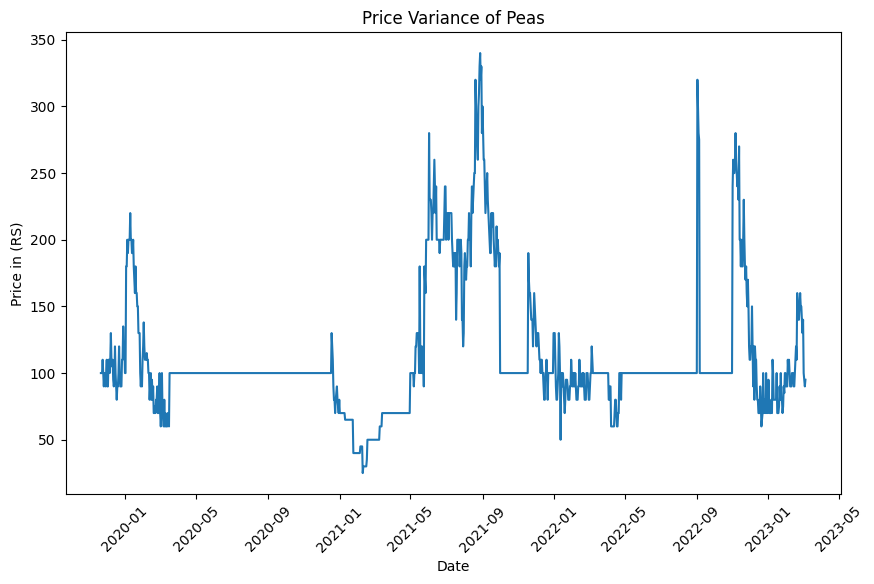

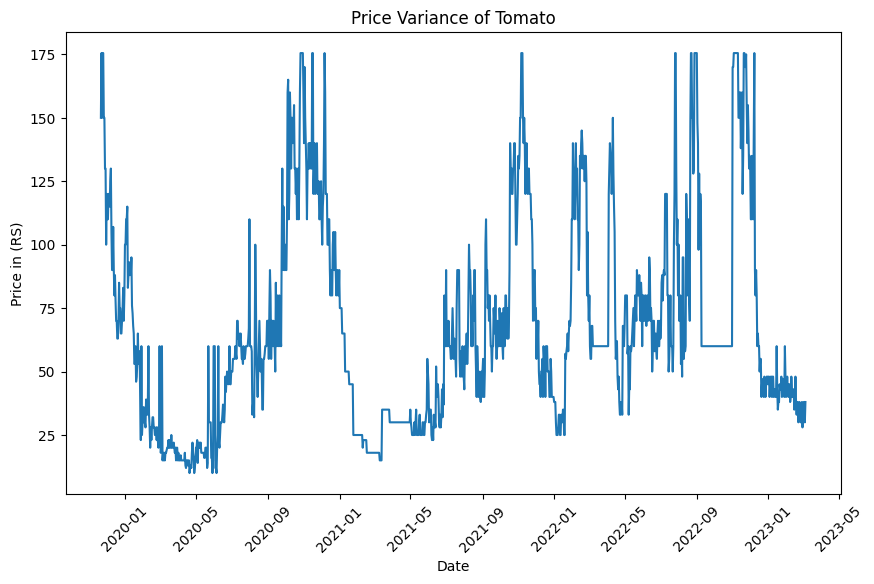

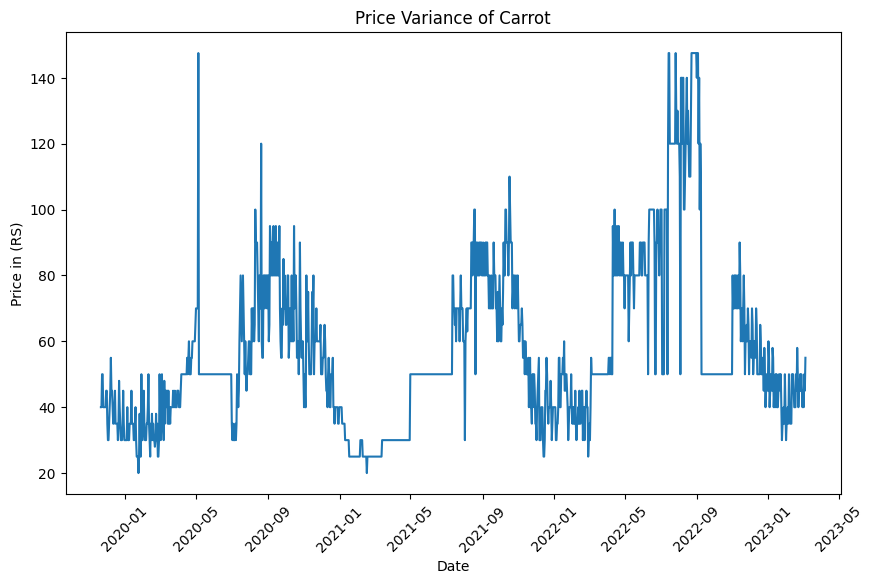

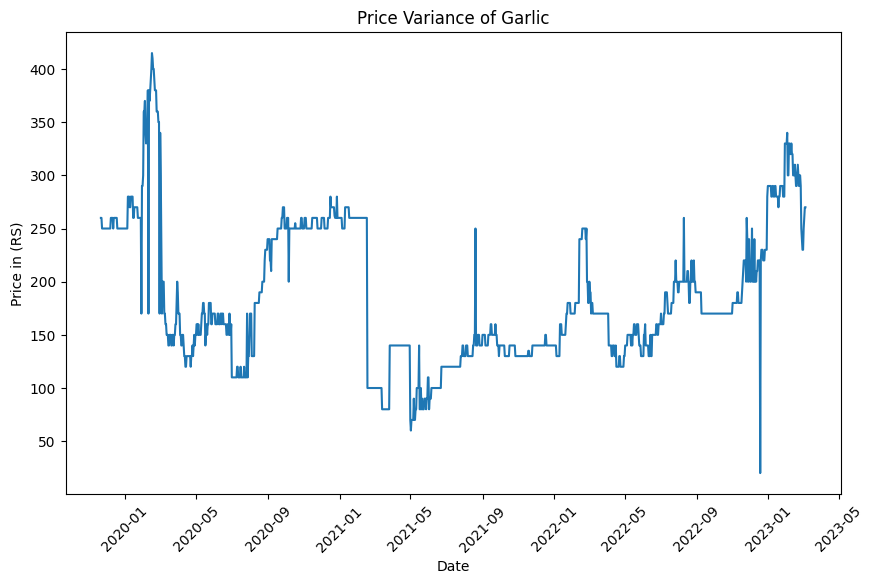

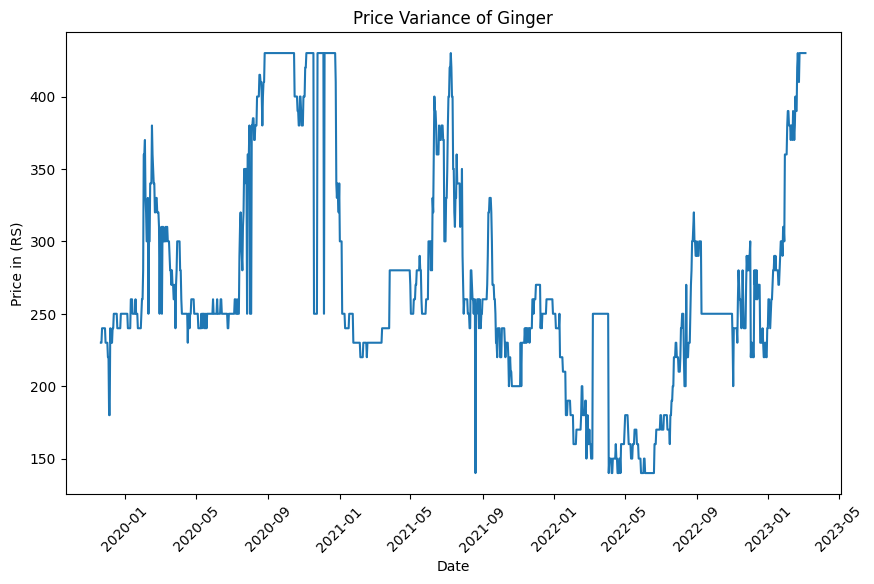

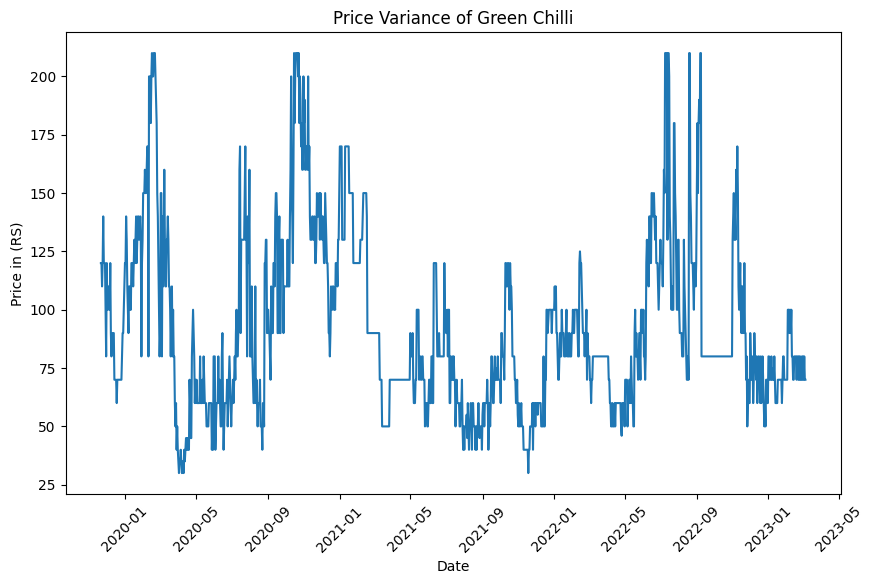

In [13]:
# Line Plot
for col in df.columns:
    plt.figure(figsize=(10,6))

    # plot the price variance over time
    sns.lineplot(x= df.index, y=df[col])
    plt.xlabel('Date')
    plt.ylabel('Price in (RS)')
    plt.title('Price Variance of '+col)
    plt.xticks(rotation=45)
    plt.show()

### Vegetables Sold Count Against Prices

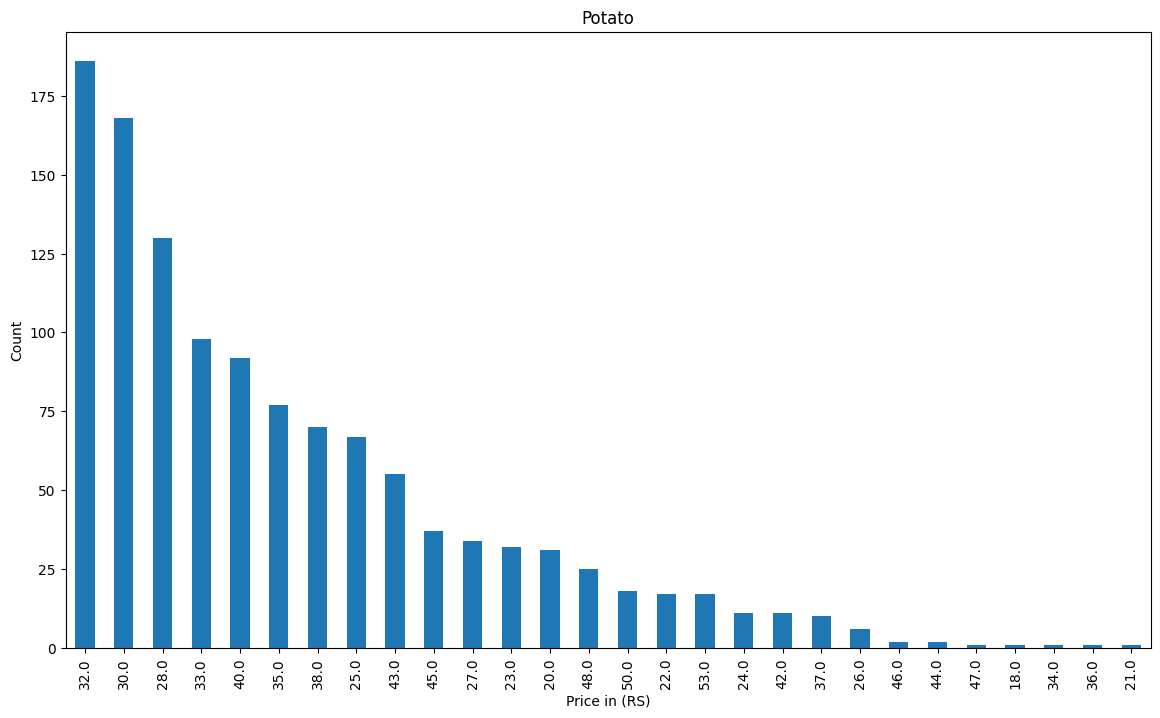

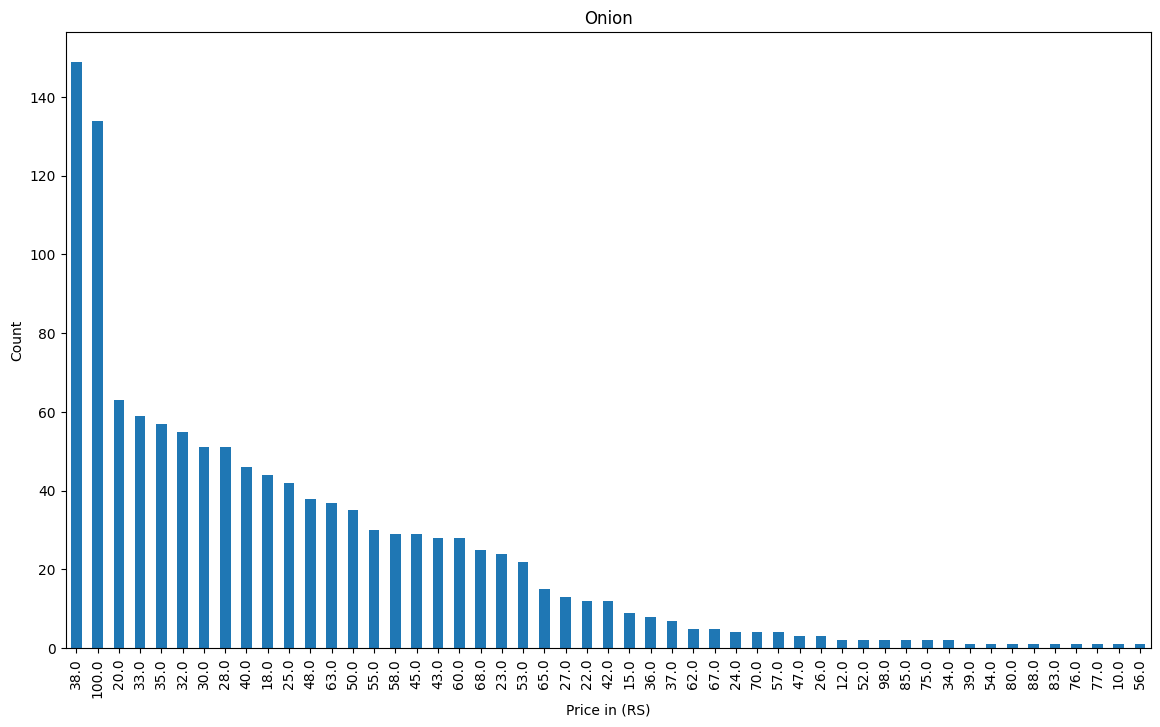

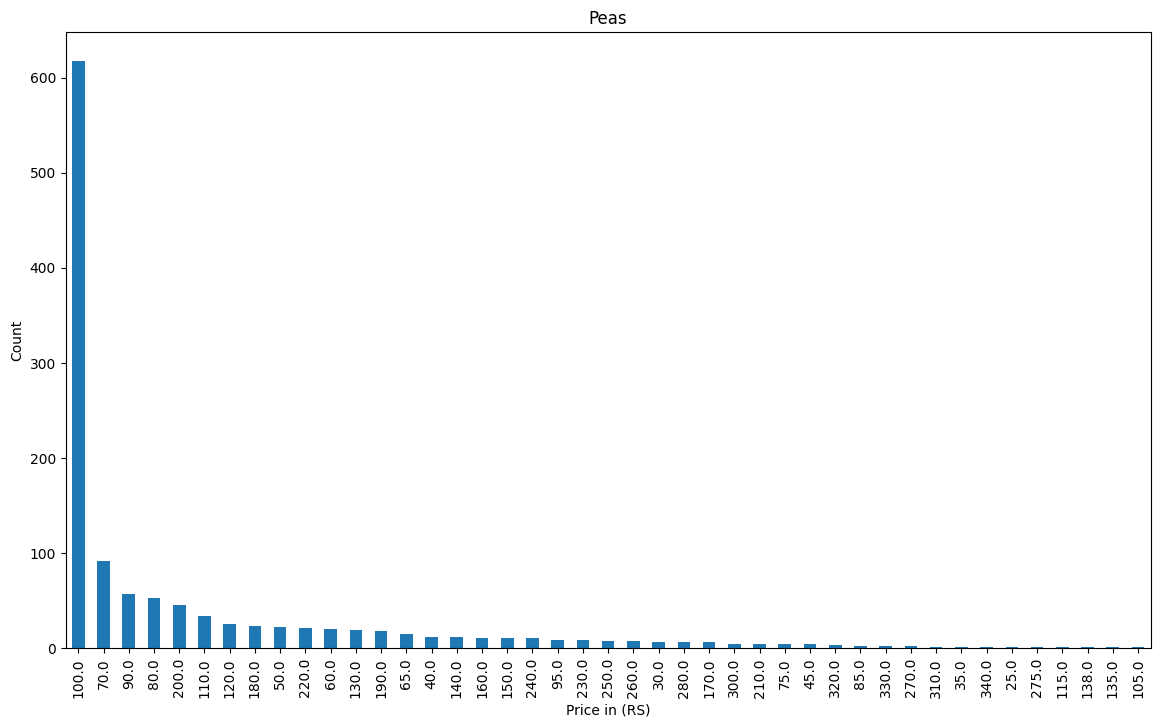

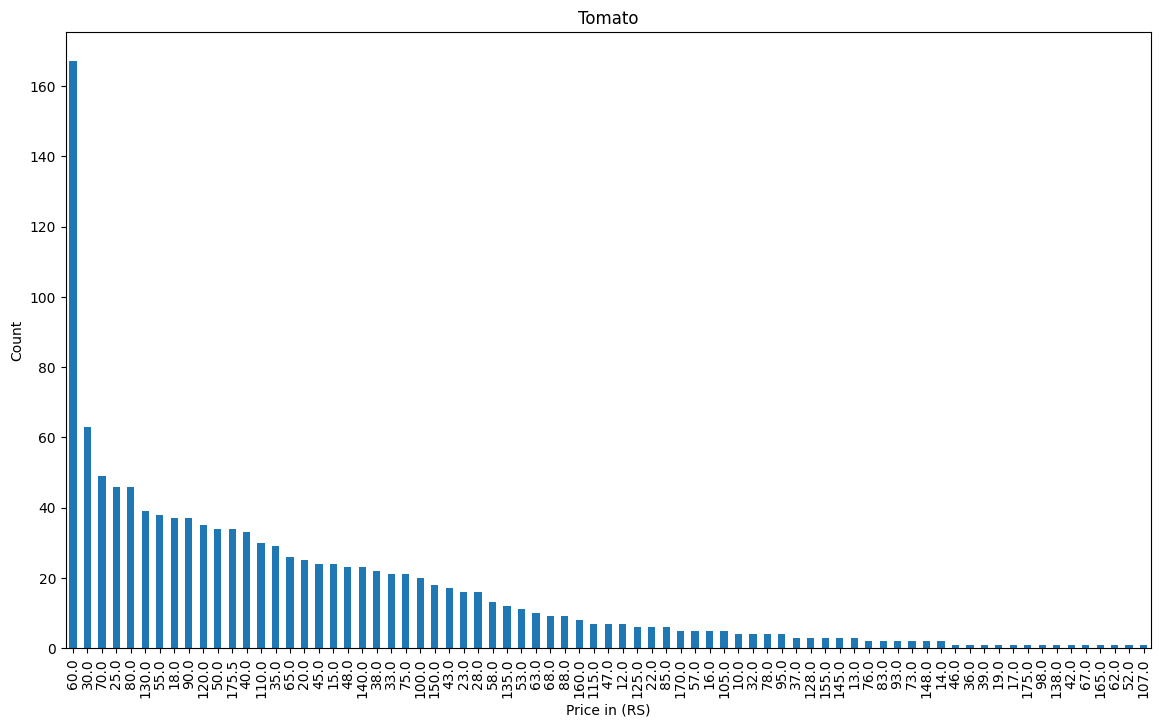

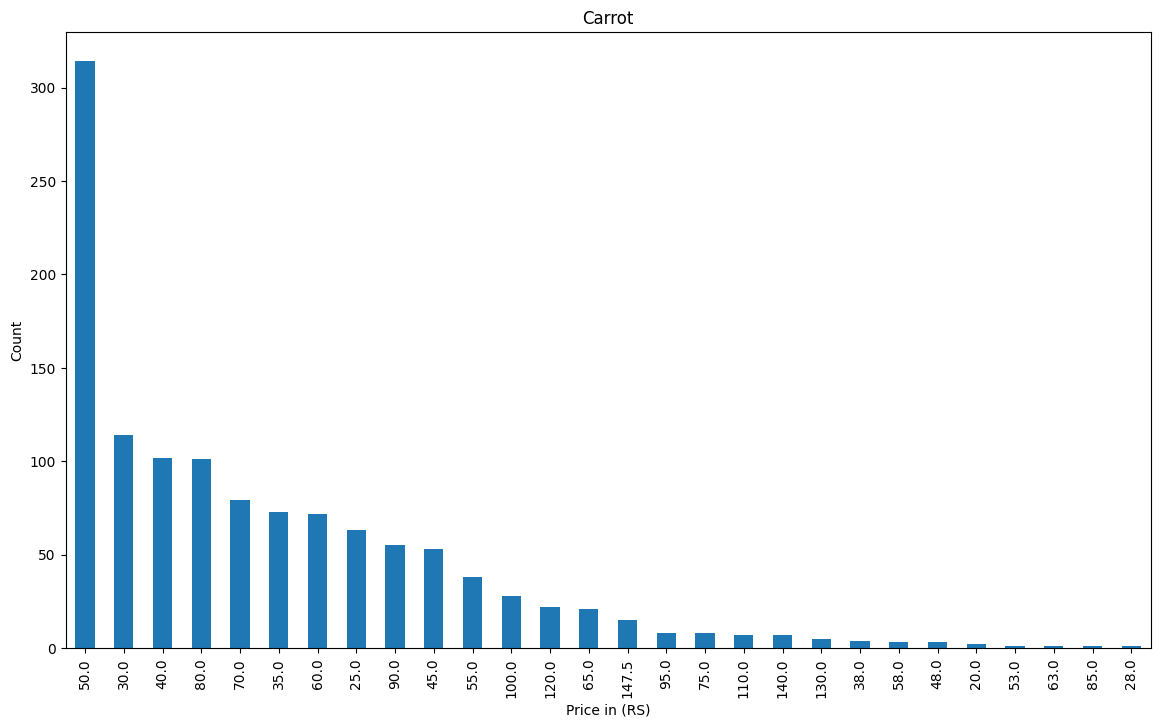

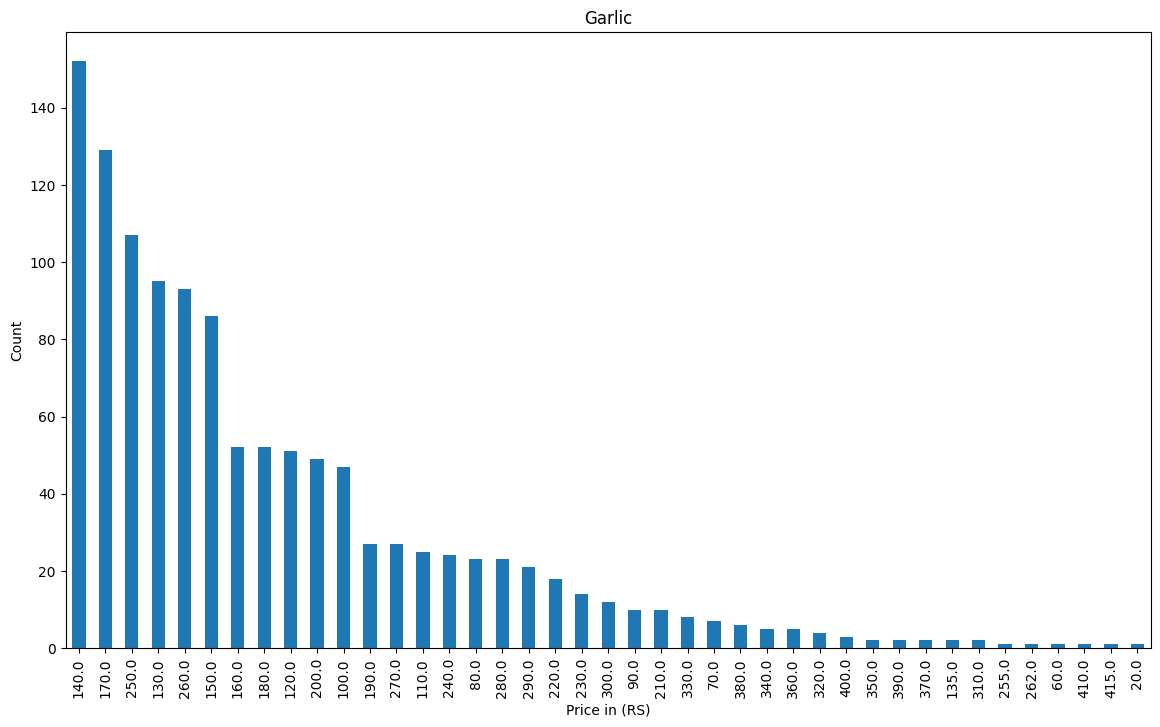

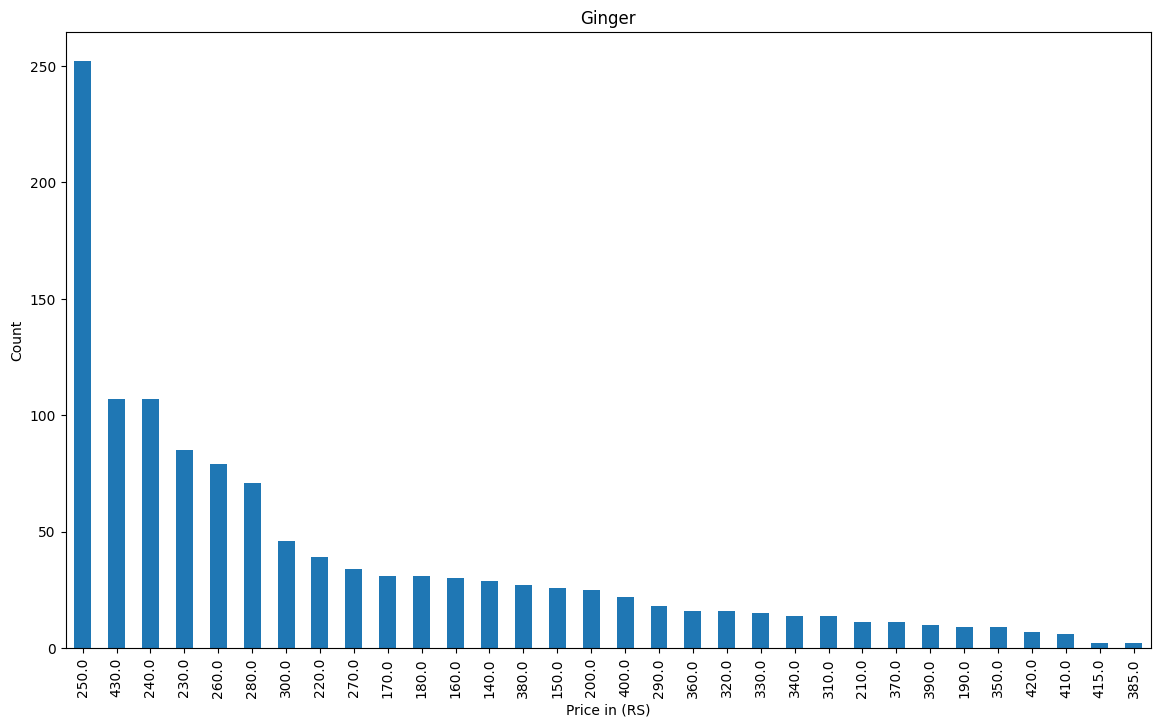

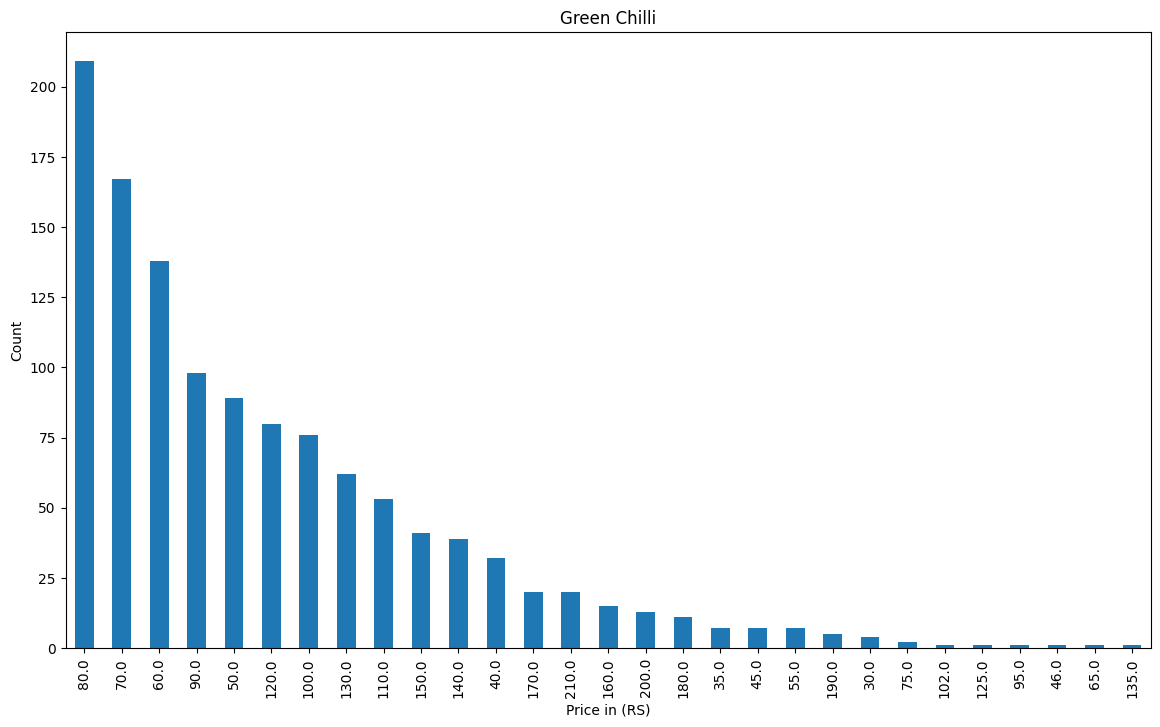

In [14]:
for col in df.columns:
    plt.figure(figsize=(14,8))
    df[col].value_counts().plot(kind='bar')
    plt.title(col)
    plt.xlabel('Price in (RS)')
    plt.ylabel('Count')
    plt.xticks(rotation=90)
    plt.show()

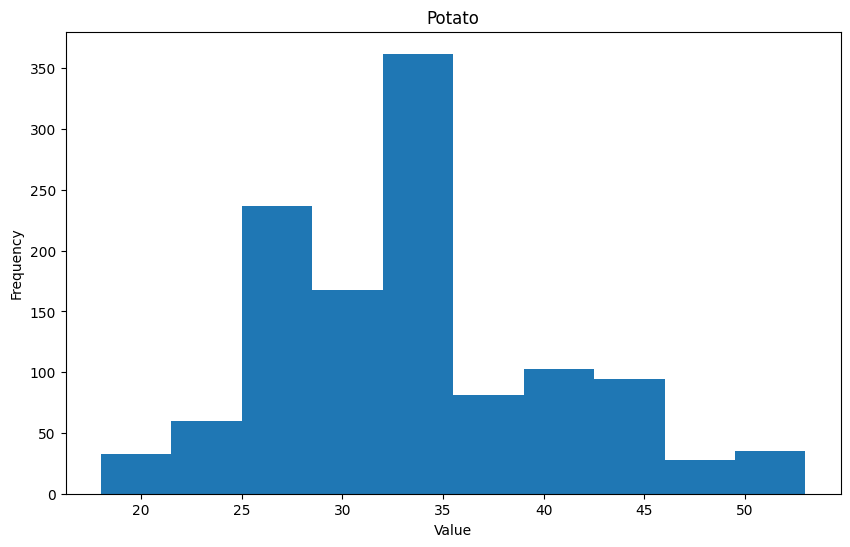

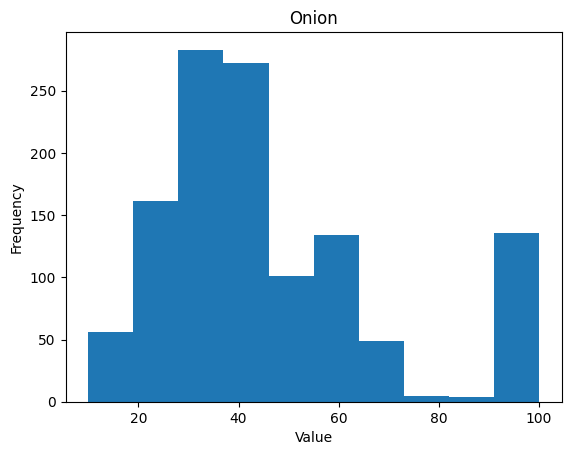

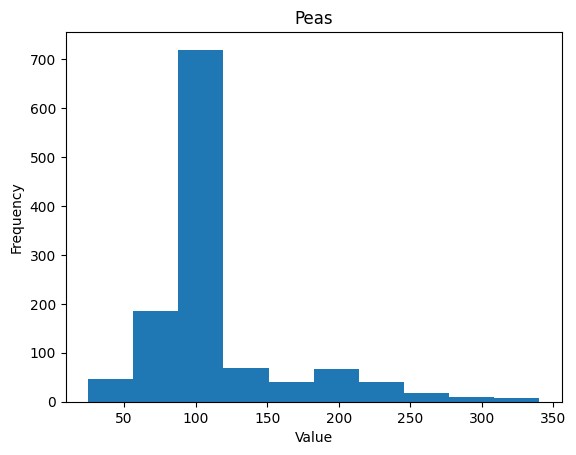

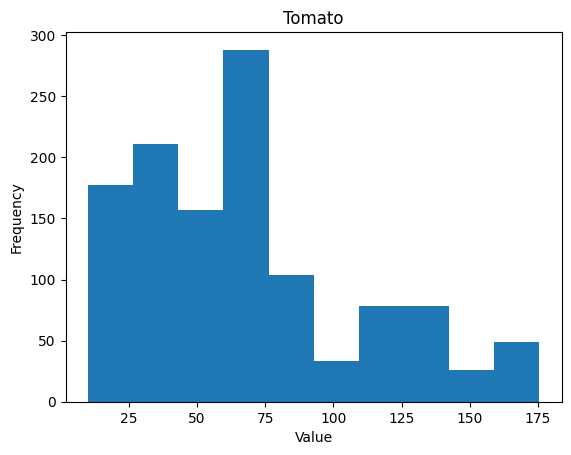

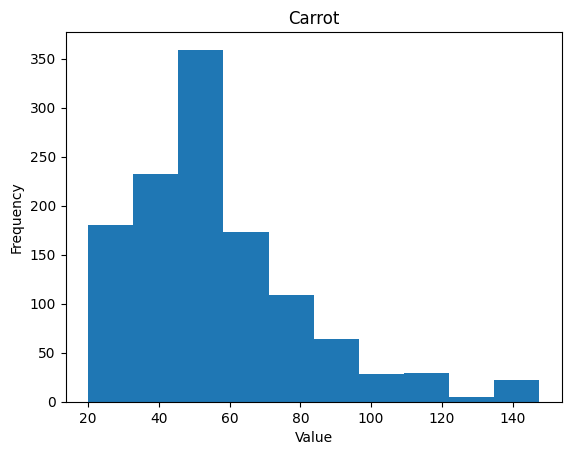

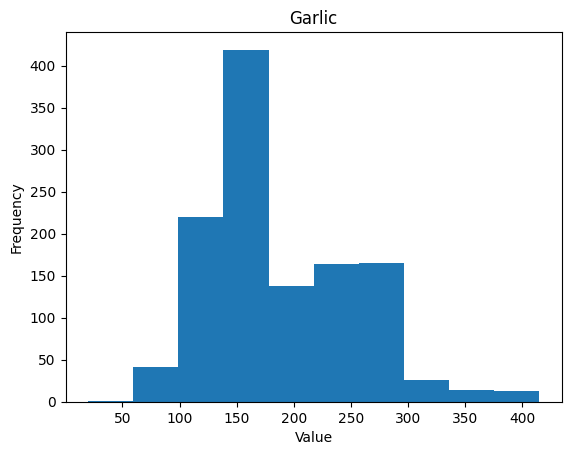

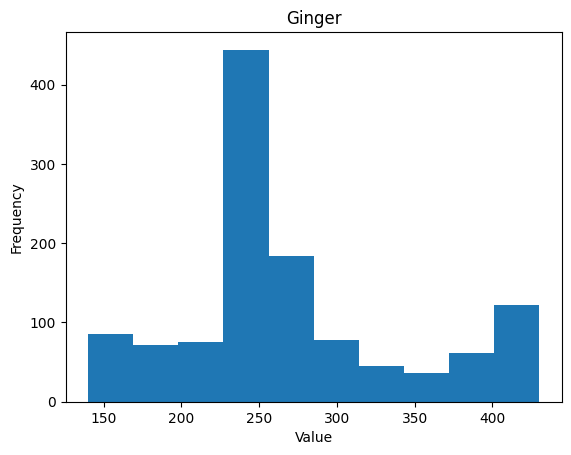

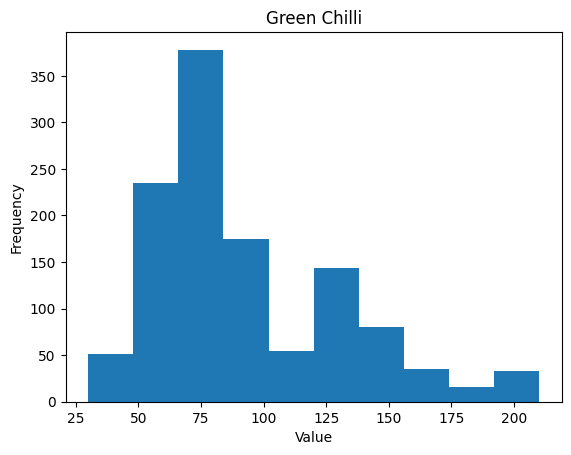

In [15]:
plt.figure(figsize=(10,6))

for col in df.columns:
    plt.hist(df[col])
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.title(col)
    plt.show()

### Comparing Price Distribution

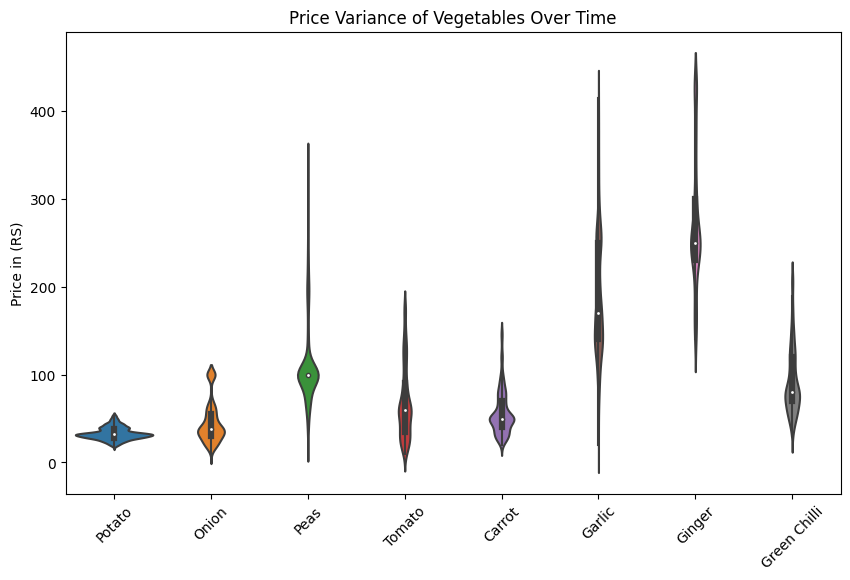

In [16]:
plt.figure(figsize=(10,6))
sns.violinplot(data=df)
plt.title('Price Variance of Vegetables Over Time')
plt.ylabel("Price in (RS)")
plt.xticks(rotation=45)
plt.show()

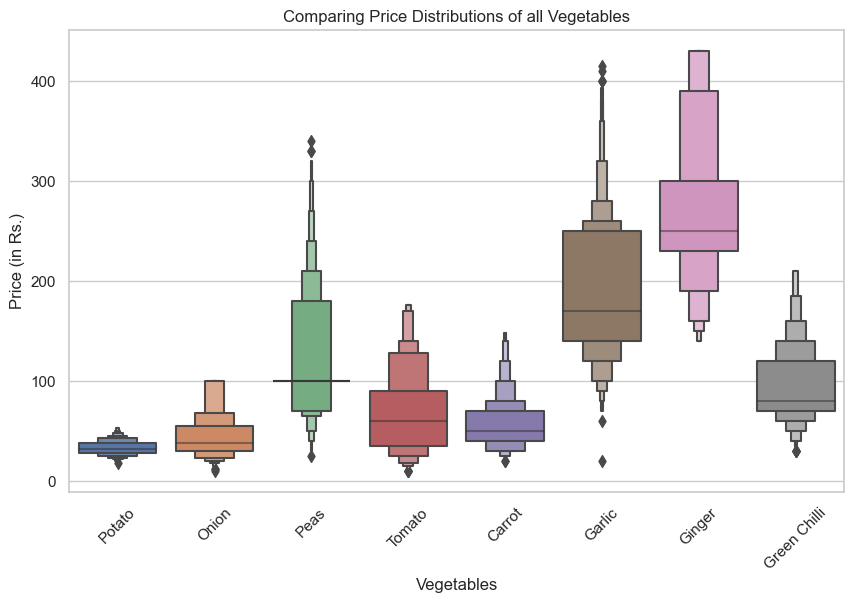

In [17]:
plt.figure(figsize=(10,6))
sns.set(style="whitegrid")
ax = sns.boxenplot(data=df)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
ax.set_xlabel("Vegetables")
ax.set_ylabel("Price (in Rs.)")
ax.set_title("Comparing Price Distributions of all Vegetables")
plt.show()

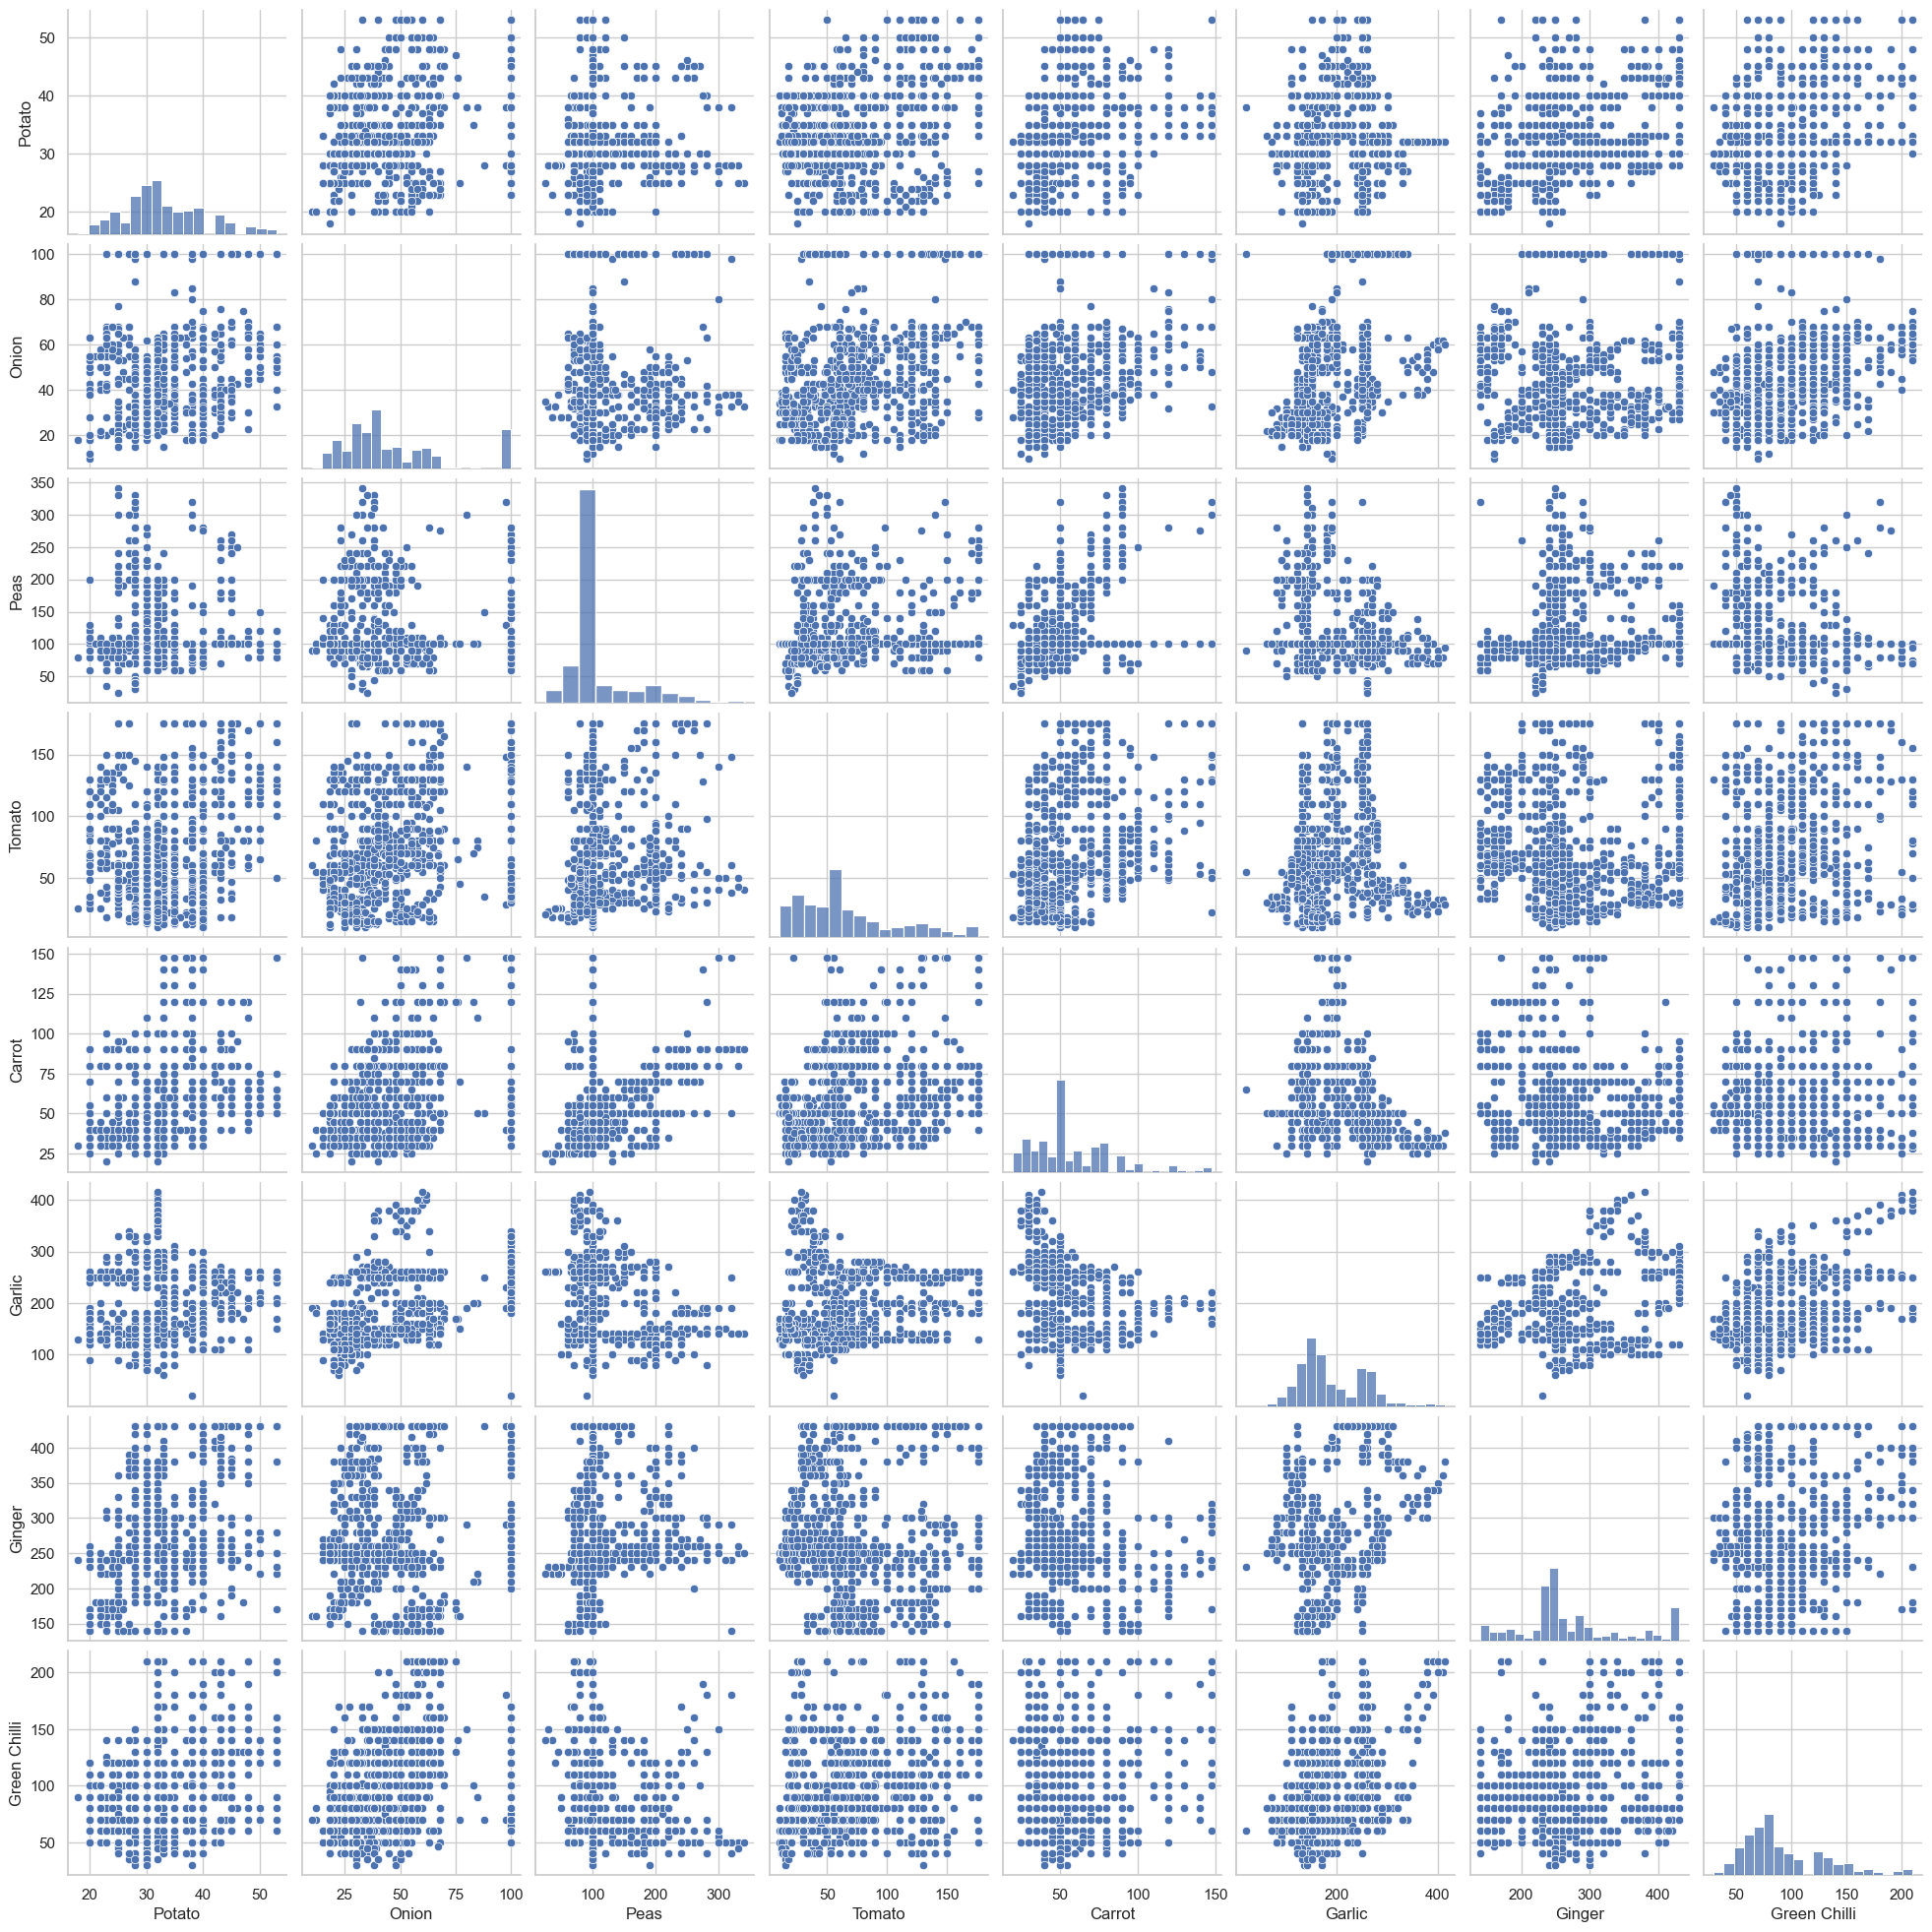

In [18]:
sns.pairplot(df)
plt.show()

### Price Correlation Between Vegetables

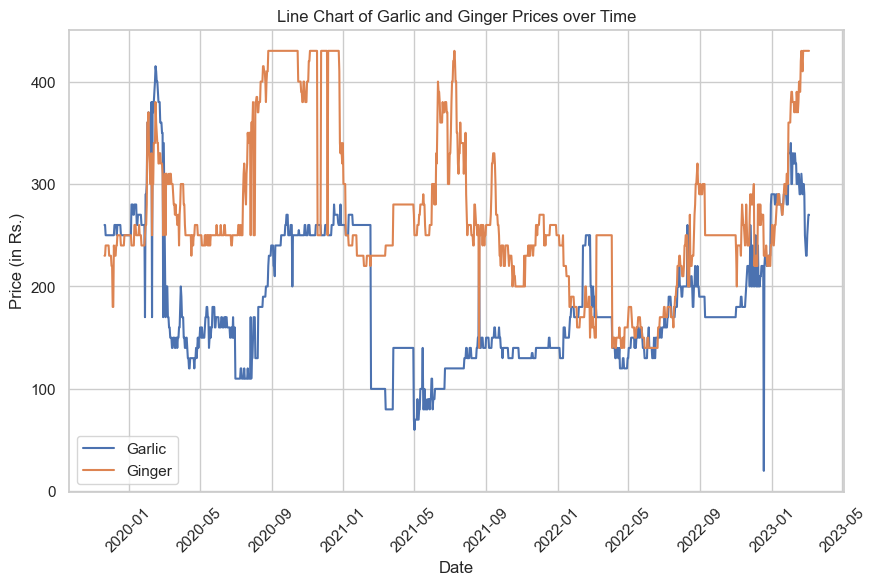

In [19]:
plt.figure(figsize=(10,6))
plt.plot(df.index, df["Garlic"], label="Garlic")
plt.plot(df.index, df["Ginger"], label="Ginger")
plt.legend()
plt.xlabel("Date")
plt.ylabel("Price (in Rs.)")
plt.xticks(rotation=45)
plt.title("Line Chart of Garlic and Ginger Prices over Time")
plt.show()

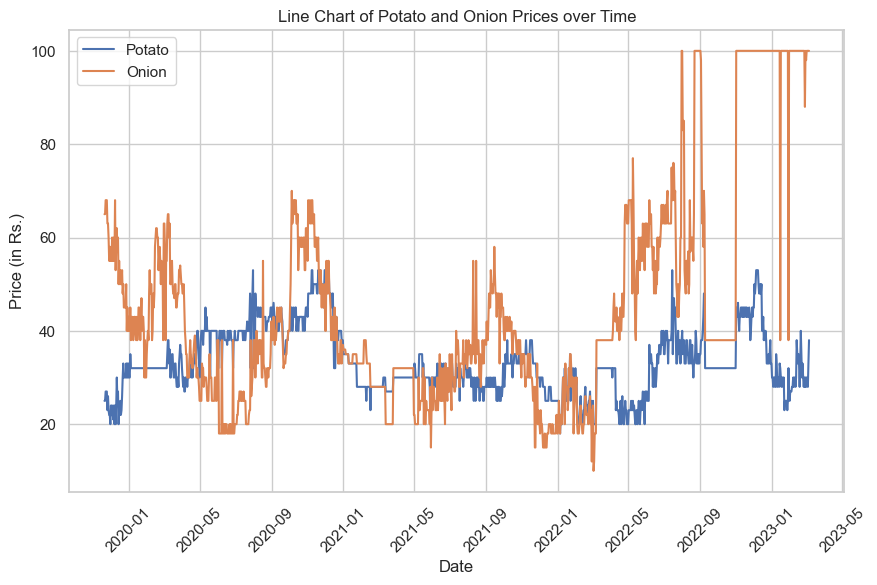

In [20]:
plt.figure(figsize=(10,6))
plt.plot(df.index, df["Potato"], label="Potato")
plt.plot(df.index, df["Onion"], label="Onion")
plt.legend()
plt.xlabel("Date")
plt.ylabel("Price (in Rs.)")
plt.xticks(rotation=45)
plt.title("Line Chart of Potato and Onion Prices over Time")
plt.show()

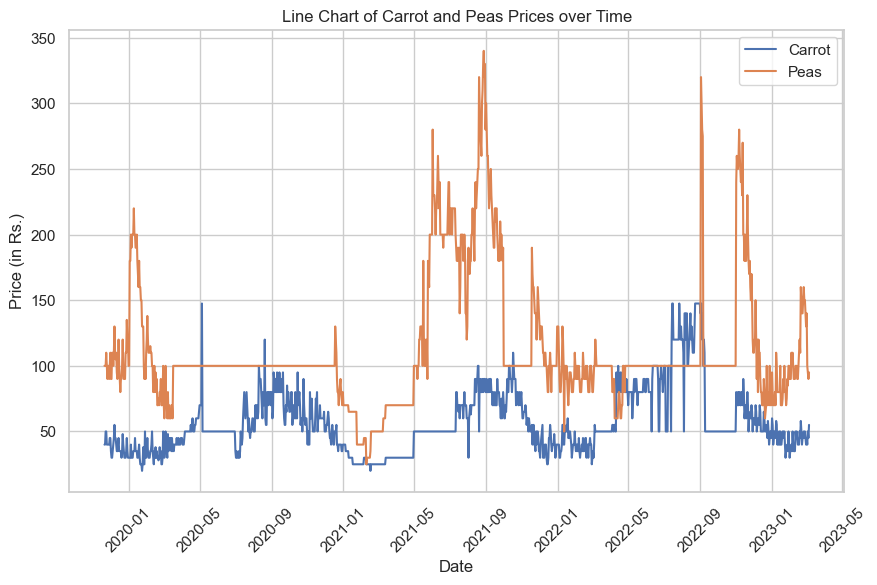

In [21]:
plt.figure(figsize=(10,6))
plt.plot(df.index, df["Carrot"], label="Carrot")
plt.plot(df.index, df["Peas"], label="Peas")
plt.legend()
plt.xlabel("Date")
plt.ylabel("Price (in Rs.)")
plt.xticks(rotation=45)
plt.title("Line Chart of Carrot and Peas Prices over Time")
plt.show()

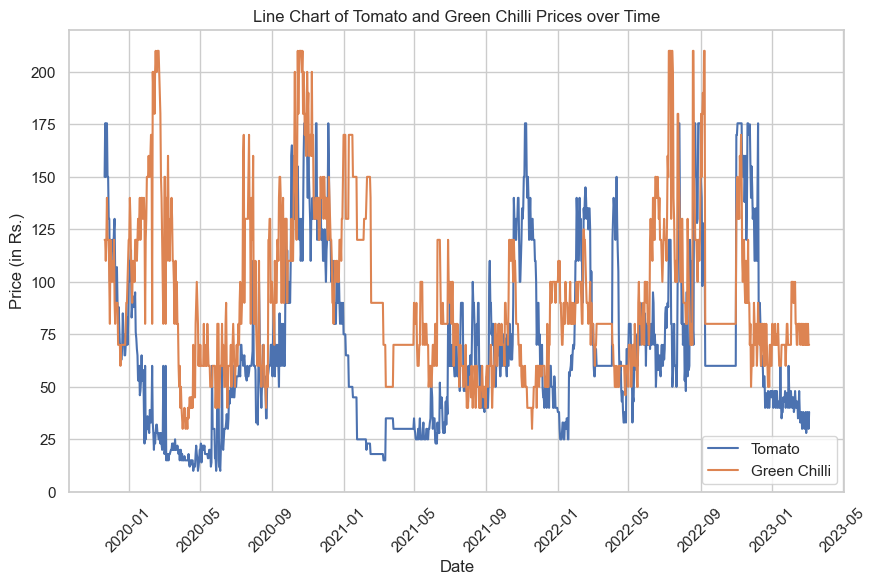

In [22]:
plt.figure(figsize=(10,6))
plt.plot(df.index, df["Tomato"], label="Tomato")
plt.plot(df.index, df["Green Chilli"], label="Green Chilli")
plt.legend()
plt.xlabel("Date")
plt.ylabel("Price (in Rs.)")
plt.xticks(rotation=45)
plt.title("Line Chart of Tomato and Green Chilli Prices over Time")
plt.show()

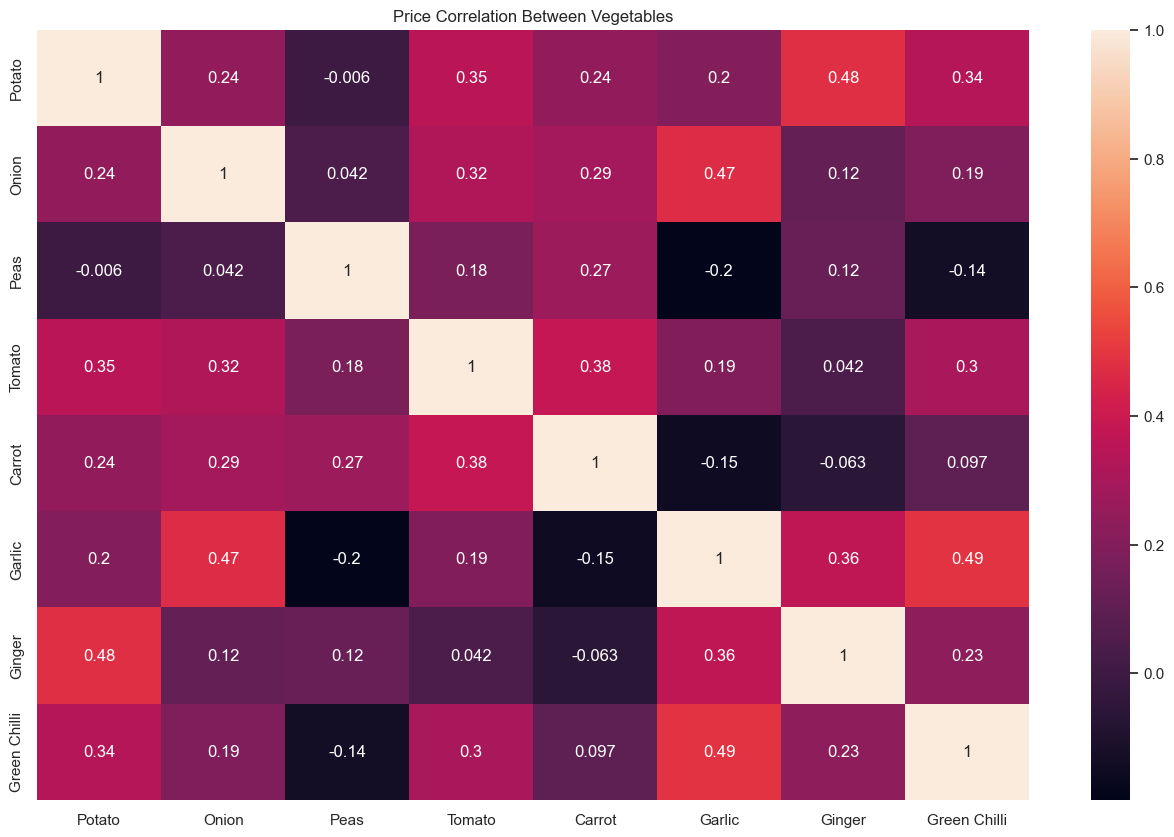

In [23]:
plt.figure(figsize=(16,10))
corr = df.corr()
sns.heatmap(corr,annot=True)
plt.title("Price Correlation Between Vegetables")
plt.show()

# TRAINING USING SARIMA MODEL

In [24]:
# Finding the order for the model
# for i in df.columns:
#     stepwise_fit= auto_arima(df[i], seasonal=True, m=12, suppress_warnings=True, error_action='ignore', trace=True)
#     print(i, "\n", stepwise_fit.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=5658.420, Time=2.98 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=5835.953, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=5744.813, Time=0.36 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=5695.700, Time=0.42 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=5833.972, Time=0.03 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=5656.824, Time=1.75 sec
 ARIMA(2,1,2)(0,0,0)[12] intercept   : AIC=5655.775, Time=0.74 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=5656.794, Time=1.88 sec
 ARIMA(1,1,2)(0,0,0)[12] intercept   : AIC=5662.517, Time=0.30 sec
 ARIMA(2,1,1)(0,0,0)[12] intercept   : AIC=5662.512, Time=0.27 sec
 ARIMA(3,1,2)(0,0,0)[12] intercept   : AIC=5656.632, Time=0.89 sec
 ARIMA(2,1,3)(0,0,0)[12] intercept   : AIC=5657.077, Time=0.99 sec
 ARIMA(1,1,1)(0,0,0)[12] intercept   : AIC=5660.592, Time=0.19 sec
 ARIMA(1,1,3)(0,0,0)[12] intercept   : AIC=5664.471, Time=0.62 sec
 ARIMA(3,1,1)(0,0,0

 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=9935.656, Time=2.28 sec
 ARIMA(1,1,2)(0,0,0)[12] intercept   : AIC=9932.808, Time=0.59 sec
 ARIMA(1,1,2)(1,0,0)[12] intercept   : AIC=9934.786, Time=1.36 sec
 ARIMA(1,1,2)(0,0,1)[12] intercept   : AIC=9934.783, Time=1.63 sec
 ARIMA(1,1,2)(1,0,1)[12] intercept   : AIC=9936.302, Time=3.52 sec
 ARIMA(0,1,2)(0,0,0)[12] intercept   : AIC=9945.054, Time=0.25 sec
 ARIMA(1,1,1)(0,0,0)[12] intercept   : AIC=9933.110, Time=0.32 sec
 ARIMA(1,1,3)(0,0,0)[12] intercept   : AIC=9928.794, Time=0.89 sec
 ARIMA(1,1,3)(1,0,0)[12] intercept   : AIC=9930.793, Time=1.47 sec
 ARIMA(1,1,3)(0,0,1)[12] intercept   : AIC=9930.793, Time=2.10 sec
 ARIMA(1,1,3)(1,0,1)[12] intercept   : AIC=9932.133, Time=3.83 sec
 ARIMA(0,1,3)(0,0,0)[12] intercept   : AIC=9939.159, Time=0.41 sec
 ARIMA(2,1,3)(0,0,0)[12] intercept   : AIC=inf, Time=2.05 sec
 ARIMA(1,1,4)(0,0,0)[12] intercept   : AIC=9912.461, Time=0.67 sec
 ARIMA(1,1,4)(1,0,0)[12] intercept   : AIC=9914.441, Time=1.21 sec


KeyboardInterrupt: 

### Predicting Potato Prices

In [7]:
# Select only the first column for modeling
data = df.iloc[:, 0]

# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(np.array(data).reshape(-1, 1))

# Split the data into training and testing sets
train_size = int(len(scaled_data) * 0.8)
train_data, test_data, date = scaled_data[:train_size], scaled_data[train_size:], data.index[train_size:]

MAE:  8.31671880864422
RMSE:  10.021706632197795


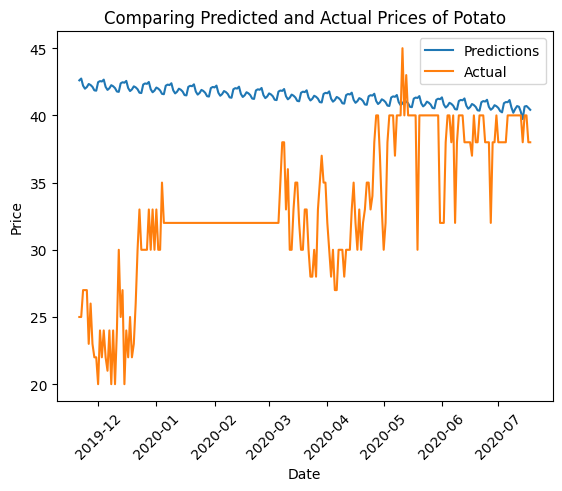

In [8]:
# Fit the SARIMA model
model = SARIMAX(train_data, order=(2,1,2), seasonal_order=(2,1,2,12))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.forecast(steps=len(test_data))

# Rescale the predicted and actual prices to their original range
y_pred_potato = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_potato = scaler.inverse_transform(test_data.reshape(-1, 1))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_potato, y_pred_potato))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_potato, y_pred_potato)))

# Plot the predicted and actual values
plt.plot(date, y_pred_potato, label="Predictions")
plt.plot(date, y_test_potato, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Potato")
plt.legend()
plt.show()

### Predicting Onion Prices

In [9]:
# Select only the second column for modeling
data = df.iloc[:, 1]

# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(np.array(data).reshape(-1, 1))

# Split the data into training and testing sets
train_size = int(len(scaled_data) * 0.8)
train_data, test_data,date = scaled_data[:train_size], scaled_data[train_size:], data.index[train_size:]

MAE:  30.03288125304479
RMSE:  35.407272790581125


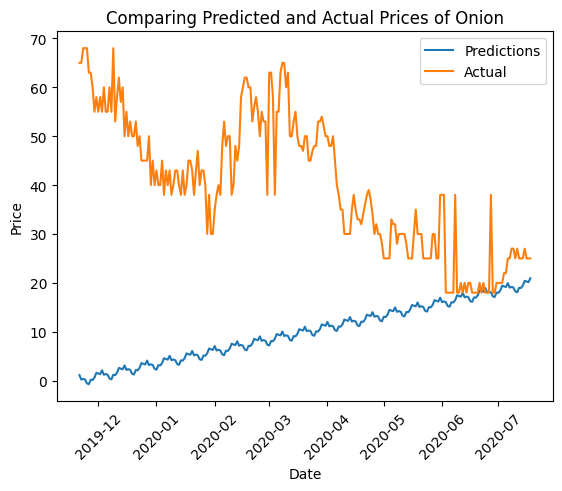

In [10]:
# Fit the SARIMA model
model = SARIMAX(train_data, order=(0,1,1), seasonal_order=(0,1,1,12))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.forecast(steps=len(test_data))

# Rescale the predicted and actual prices to their original range
y_pred_onion = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_onion = scaler.inverse_transform(test_data.reshape(-1, 1))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_onion, y_pred_onion))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_onion, y_pred_onion)))

# Plot the predicted and actual values
plt.plot(date, y_pred_onion, label="Predictions")
plt.plot(date, y_test_onion, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Onion")
plt.legend()
plt.show()

### Predicting Peas Prices

In [11]:
# Select only the second column for modeling
data = df.iloc[:, 2]

# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(np.array(data).reshape(-1, 1))

# Split the data into training and testing sets
train_size = int(len(scaled_data) * 0.8)
train_data, test_data, date = scaled_data[:train_size], scaled_data[train_size:], data.index[train_size:]

MAE:  14.59120141785636
RMSE:  28.561960136093084


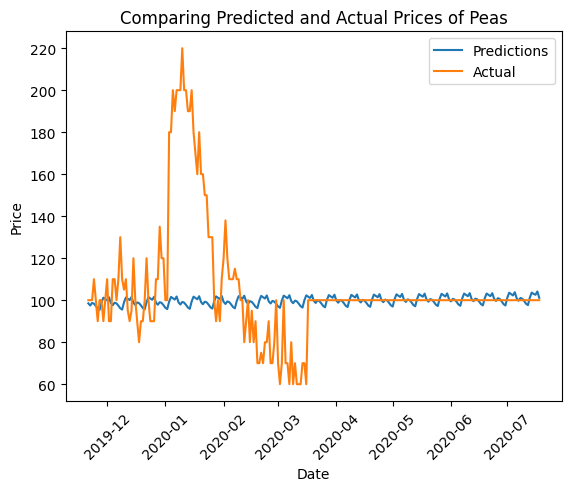

In [12]:
# Fit the SARIMA model
model = SARIMAX(train_data, order=(0,1,4), seasonal_order=(0,1,4,12))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.forecast(steps=len(test_data))

# Rescale the predicted and actual prices to their original range
y_pred_peas = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_peas = scaler.inverse_transform(test_data.reshape(-1, 1))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_peas, y_pred_peas))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_peas, y_pred_peas)))

# Plot the predicted and actual values
plt.plot(date, y_pred_peas, label="Predictions")
plt.plot(date, y_test_peas, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Peas")
plt.legend()
plt.show()

### Predicting Tomato Prices

In [13]:
# Select only the second column for modeling
data = df.iloc[:, 3]

# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(np.array(data).reshape(-1, 1))

# Split the data into training and testing sets
train_size = int(len(scaled_data) * 0.8)
train_data, test_data, date = scaled_data[:train_size], scaled_data[train_size:], data.index[train_size:]

MAE:  32.758666286993105
RMSE:  38.586173408555304


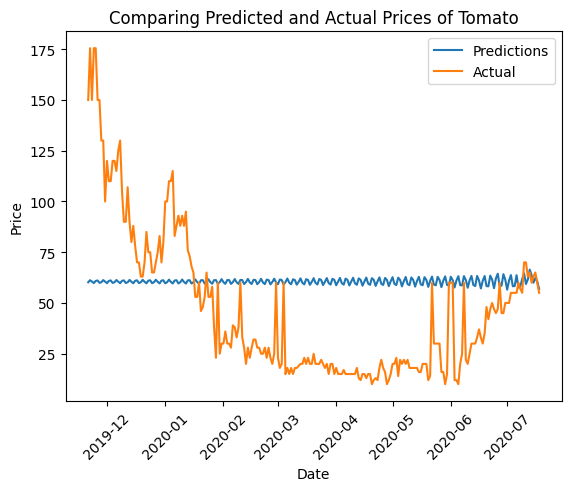

In [14]:
# Fit the SARIMA model
model = SARIMAX(train_data, order=(4,1,5), seasonal_order=(2,0,0,12))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.forecast(steps=len(test_data))

# Rescale the predicted and actual prices to their original range
y_pred_tomato = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_tomato = scaler.inverse_transform(test_data.reshape(-1, 1))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_tomato, y_pred_tomato))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_tomato, y_pred_tomato)))

# Plot the predicted and actual values
plt.plot(date, y_pred_tomato, label="Predictions")
plt.plot(date, y_test_tomato, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Tomato")
plt.legend()
plt.show()

### Predicting Carrot Prices

In [62]:
# Select only the second column for modeling
data = df.iloc[:, 4]

# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(np.array(data).reshape(-1, 1))

# Split the data into training and testing sets
train_size = int(len(scaled_data) * 0.8)
train_data, test_data, date = scaled_data[:train_size], scaled_data[train_size:], data.index[train_size:]

MAE:  26.829304708630172
RMSE:  29.074138650447814


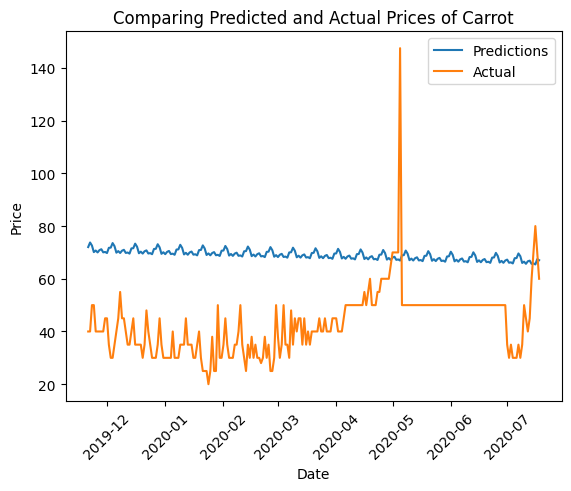

In [63]:
# Fit the SARIMA model
model = SARIMAX(train_data, order=(0,1,2), seasonal_order=(0,1,2,12))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.forecast(steps=len(test_data))

# Rescale the predicted and actual prices to their original range
y_pred_carrot = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_carrot = scaler.inverse_transform(test_data.reshape(-1, 1))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_carrot, y_pred_carrot))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_carrot, y_pred_carrot)))

# Plot the predicted and actual values
plt.plot(date, y_pred_carrot, label="Predictions")
plt.plot(date, y_test_carrot, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Carrot")
plt.legend()
plt.show()

### Predicting Garlic Prices

In [17]:
# Select only the garlic column for modeling
data = df.iloc[:, 5]

# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(np.array(data).reshape(-1, 1))

# Split the data into training and testing sets
train_size = int(len(scaled_data) * 0.8)
train_data, test_data, date = scaled_data[:train_size], scaled_data[train_size:], data.index[train_size:]

MAE:  124.17760433151697
RMSE:  152.52904359335437


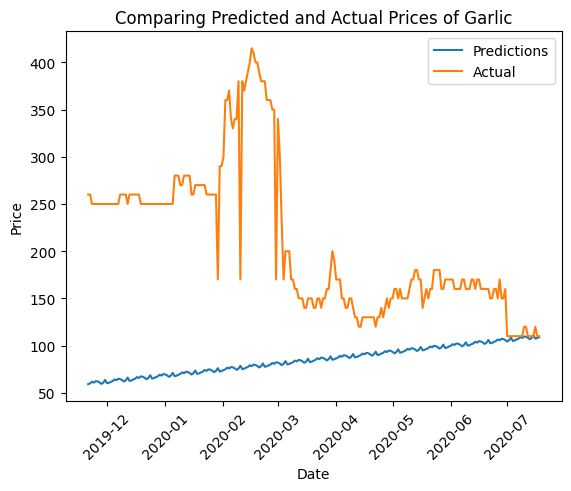

In [18]:
# Fit the SARIMA model
model = SARIMAX(train_data, order=(0,1,1), seasonal_order=(0,1,1,12))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.forecast(steps=len(test_data))

# Rescale the predicted and actual prices to their original range
y_pred_garlic = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_garlic = scaler.inverse_transform(test_data.reshape(-1, 1))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_garlic, y_pred_garlic))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_garlic, y_pred_garlic)))

# Plot the predicted and actual values
plt.plot(date, y_pred_garlic, label="Predictions")
plt.plot(date, y_test_garlic, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Garlic")
plt.legend()
plt.show()

### Predicting Ginger Prices

In [19]:
# Select only the ginger column for modeling
data = df.iloc[:, 6]

# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(np.array(data).reshape(-1, 1))

# Split the data into training and testing sets
train_size = int(len(scaled_data) * 0.8)
train_data, test_data, date = scaled_data[:train_size], scaled_data[train_size:], data.index[train_size:]

MAE:  53.44267228225409
RMSE:  67.48745581220957


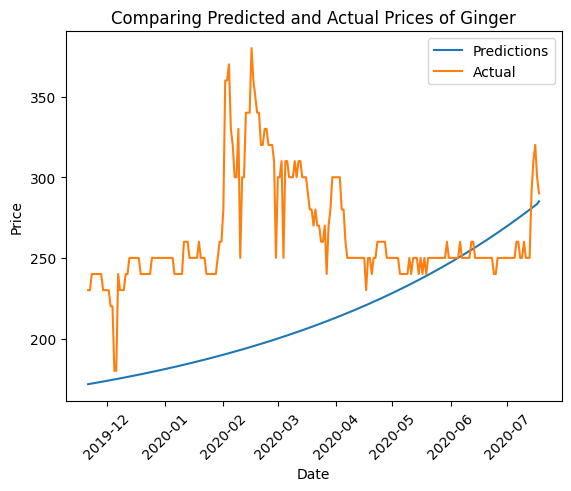

In [20]:
# Fit the SARIMA model
model = SARIMAX(train_data, order=(3,0,0), seasonal_order=(0,0,0,12))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.forecast(steps=len(test_data))

# Rescale the predicted and actual prices to their original range
y_pred_ginger = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_ginger = scaler.inverse_transform(test_data.reshape(-1, 1))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_ginger, y_pred_ginger))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_ginger, y_pred_ginger)))

# Plot the predicted and actual values
plt.plot(date, y_pred_ginger, label="Predictions")
plt.plot(date, y_test_ginger, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Ginger")
plt.legend()
plt.show()

### Predicting Green Chili Prices

In [21]:
# Select only the green chili column for modeling
data = df.iloc[:, 7]

# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(np.array(data).reshape(-1, 1))

# Split the data into training and testing sets
train_size = int(len(scaled_data) * 0.8)
train_data, test_data, date = scaled_data[:train_size], scaled_data[train_size:], data.index[train_size:]

MAE:  52.311704049206675
RMSE:  59.278761619067424


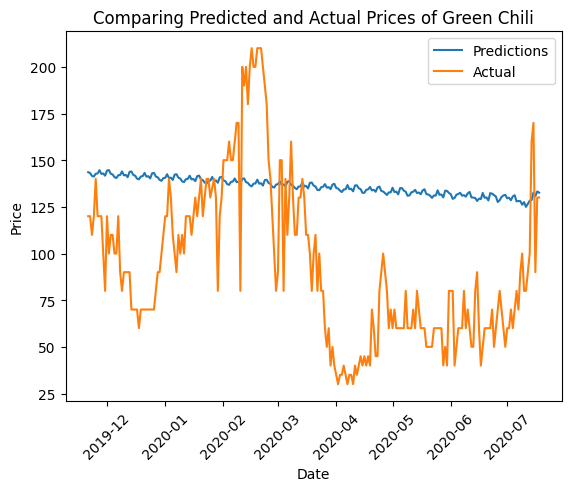

In [22]:
# Fit the SARIMA model
model = SARIMAX(train_data, order=(2,1,2), seasonal_order=(2,1,2,12))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.forecast(steps=len(test_data))

# Rescale the predicted and actual prices to their original range
y_pred_chili = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_chili = scaler.inverse_transform(test_data.reshape(-1, 1))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_chili, y_pred_chili))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_chili, y_pred_chili)))

# Plot the predicted and actual values
plt.plot(date, y_pred_chili, label="Predictions")
plt.plot(date, y_test_chili, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Green Chili")
plt.legend()
plt.show()

MAE:  5.7120464735246825
RMSE:  6.911977932499639


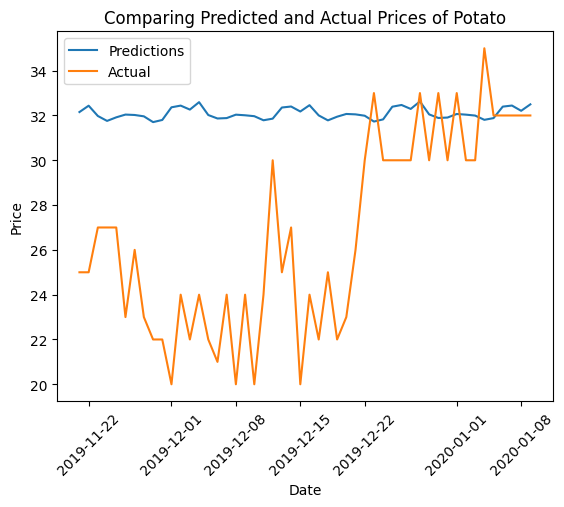

In [58]:
# (2,1,2)(0,0,0)

train,test= df["Potato"].iloc[:-50],df["Potato"].iloc[-50:]

# Fit the SARIMA model
sarima_model = SARIMAX(train, order=(2,1,2), seasonal_order=(2,1,2,12))
model_fit = sarima_model.fit()

# Generate predictions for the testing set
predictions = model_fit.forecast(steps=len(test))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(test, predictions))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(test, predictions)))

# Plot the predicted and actual values
plt.plot(test.index, predictions, label="Predictions")
plt.plot(test.index, test, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Potato")
plt.legend()
plt.show()

MAE:  5.605695392649934
RMSE:  6.888909852442254


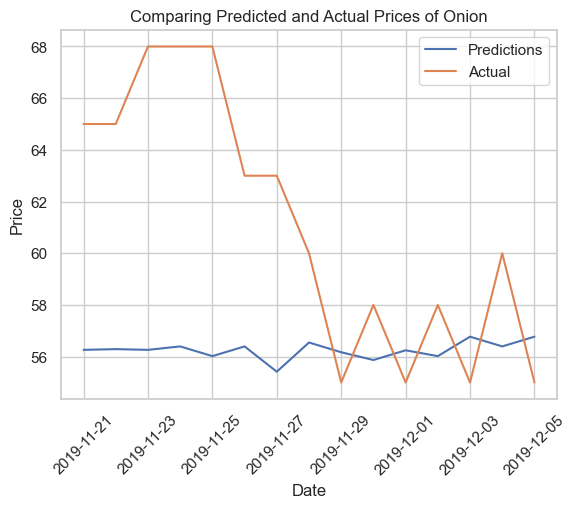

In [26]:
# (0,1,1)(1,0,0)

train,test= df["Onion"].iloc[:-15],df["Onion"].iloc[-15:]

# Fit the SARIMA model
sarima_model = SARIMAX(train, order=(0,1,1), seasonal_order=(1,0,0,12))
model_fit = sarima_model.fit()

# Generate predictions for the testing set
predictions = model_fit.forecast(steps=len(test))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(test, predictions))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(test, predictions)))

# Plot the predicted and actual values
plt.plot(test.index, predictions, label="Predictions")
plt.plot(test.index, test, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Onion")
plt.legend()
plt.show()

MAE:  8.056115347763315
RMSE:  9.674831855688057


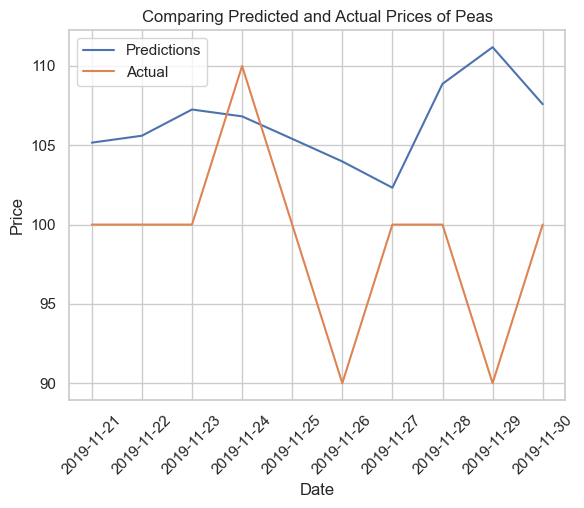

In [27]:
# (0,1,4)(0,0,0)

train,test= df["Peas"].iloc[:-10],df["Peas"].iloc[-10:]

# Fit the SARIMA model
sarima_model = SARIMAX(train, order=(0,1,4), seasonal_order=(0,1,4,12))
model_fit = sarima_model.fit()

# Generate predictions for the testing set
predictions = model_fit.forecast(steps=len(test))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(test, predictions))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(test, predictions)))

# Plot the predicted and actual values
plt.plot(test.index, predictions, label="Predictions")
plt.plot(test.index, test, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Peas")
plt.legend()
plt.show()

MAE:  16.849999999999994
RMSE:  19.98687069053081


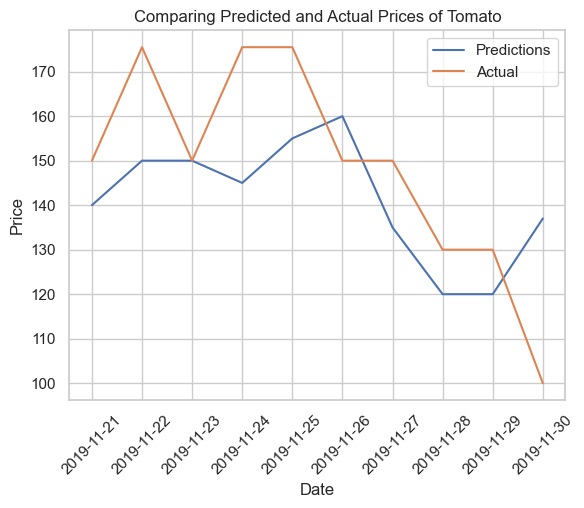

In [29]:
# (4,1,5)(2,0,0)

train,test= df["Tomato"].iloc[:-10],df["Tomato"].iloc[-10:]

# Fit the SARIMA model
sarima_model = SARIMAX(train, order=(0,1,0), seasonal_order=(0,1,0,12))
model_fit = sarima_model.fit()

# Generate predictions for the testing set
predictions = model_fit.forecast(steps=len(test))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(test, predictions))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(test, predictions)))

# Plot the predicted and actual values
plt.plot(test.index, predictions, label="Predictions")
plt.plot(test.index, test, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Tomato")
plt.legend()
plt.show()

MAE:  5.36034928753953
RMSE:  6.4444382713240405


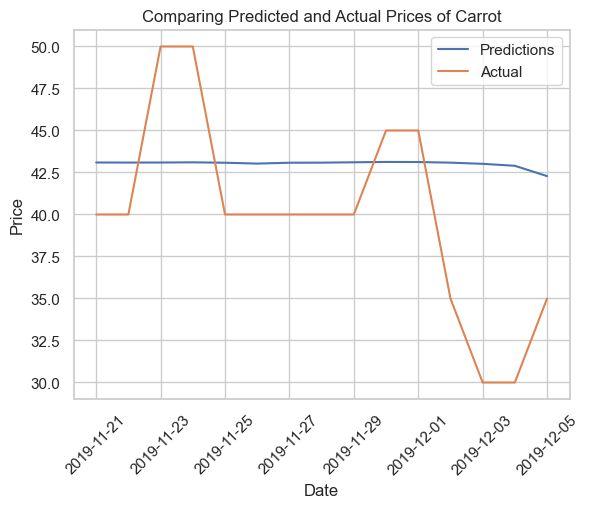

In [30]:
# (0,1,2)(0,0,0)

train,test= df["Carrot"].iloc[:-15],df["Carrot"].iloc[-15:]

# Fit the SARIMA model
sarima_model = SARIMAX(train, order=(1,1,1), seasonal_order=(1,0,1,12))
model_fit = sarima_model.fit()

# Generate predictions for the testing set
predictions = model_fit.forecast(steps=len(test))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(test, predictions))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(test, predictions)))

# Plot the predicted and actual values
plt.plot(test.index, predictions, label="Predictions")
plt.plot(test.index, test, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Carrot")
plt.legend()
plt.show()

MAE:  2.963495155641766
RMSE:  3.6211839321123427


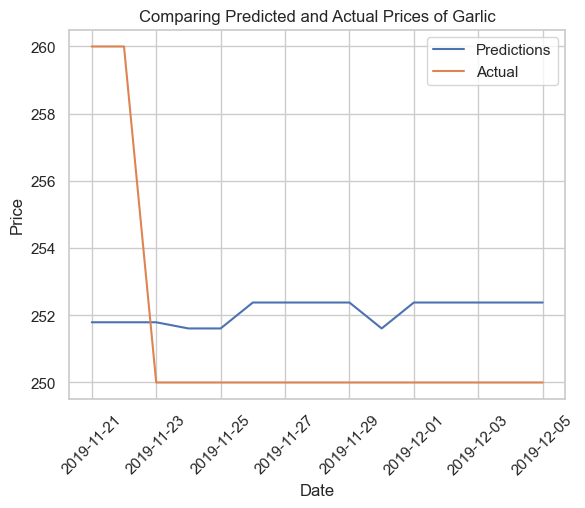

In [31]:
# (0,1,1)(1,0,0)

train,test= df["Garlic"].iloc[:-15],df["Garlic"].iloc[-15:]

# Fit the SARIMA model
sarima_model = SARIMAX(train, order=(0,1,1), seasonal_order=(1,0,0,12))
model_fit = sarima_model.fit()

# Generate predictions for the testing set
predictions = model_fit.forecast(steps=len(test))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(test, predictions))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(test, predictions)))

# Plot the predicted and actual values
plt.plot(test.index, predictions, label="Predictions")
plt.plot(test.index, test, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Garlic")
plt.legend()
plt.show()

MAE:  8.755906934044114
RMSE:  10.258005532529292


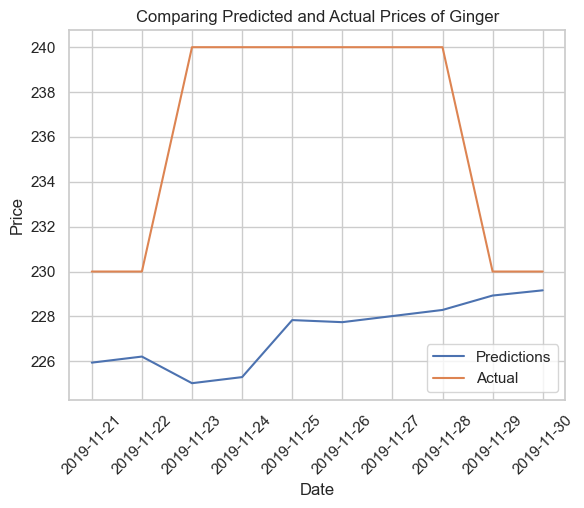

In [32]:
train,test= df["Ginger"].iloc[:-10],df["Ginger"].iloc[-10:]

# Fit the SARIMA model
sarima_model = SARIMAX(train, order=(3,0,0), seasonal_order=(3,0,0,12))
model_fit = sarima_model.fit()

# Generate predictions for the testing set
predictions = model_fit.forecast(steps=len(test))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(test, predictions))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(test, predictions)))

# Plot the predicted and actual values
plt.plot(test.index, predictions, label="Predictions")
plt.plot(test.index, test, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Ginger")
plt.legend()
plt.show()

MAE:  9.936977236858299
RMSE:  14.00842679585943


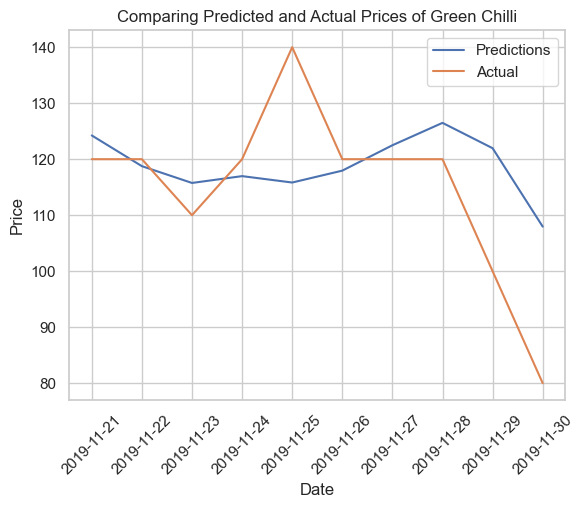

In [33]:
# (2,1,2)(0,0,0)

train,test= df["Green Chilli"].iloc[:-10],df["Green Chilli"].iloc[-10:]

# Fit the SARIMA model
sarima_model = SARIMAX(train, order=(1,1,0), seasonal_order=(2,2,2,12))
model_fit = sarima_model.fit()

# Generate predictions for the testing set
predictions = model_fit.forecast(steps=len(test))

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(test, predictions))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(test, predictions)))

# Plot the predicted and actual values
plt.plot(test.index, predictions, label="Predictions")
plt.plot(test.index, test, label="Actual")
plt.xlabel("Date")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.title("Comparing Predicted and Actual Prices of Green Chilli")
plt.legend()
plt.show()

# TRAINING USING LSTM MODEL

In [23]:
# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(df.values)

train_size = int(len(scaled) * 0.8)
train, test = scaled[:train_size], scaled[train_size:]

time_steps = 60
n_features = 8

# Define the input sequences and corresponding labels
def create_sequences(dataset, time_steps):
    X, y = [], []
    for i in range(len(dataset)-time_steps):
        X.append(dataset[i:i+time_steps])
        y.append(dataset[i+time_steps])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train, time_steps)
X_test, y_test = create_sequences(test, time_steps)

X_train = np.reshape(X_train, (X_train.shape[0], time_steps, n_features))
X_test = np.reshape(X_test, (X_test.shape[0], time_steps, n_features))

model = Sequential()
model.add(LSTM(units=128, return_sequences=True, input_shape=(time_steps, n_features)))
model.add(LSTM(units=64, return_sequences=True))
model.add(LSTM(units=32))
model.add(Dense(n_features))
model.compile(optimizer='Adamax', loss='mse')

# Train the model
model.fit(X_train, y_train, epochs=150, batch_size=64, validation_data=(X_test, y_test))

# Make predictions on the test data
y_pred = model.predict(X_test)

# Rescale the predicted and actual prices to their original range
y_pred = scaler.inverse_transform(y_pred)
y_test = scaler.inverse_transform(y_test)

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test, y_pred)))

Epoch 1/150
15/15 [==============================] - 11s 320ms/step - loss: 0.0717 - val_loss: 0.0339
Epoch 2/150
15/15 [==============================] - 2s 153ms/step - loss: 0.0315 - val_loss: 0.0302
Epoch 3/150
15/15 [==============================] - 3s 201ms/step - loss: 0.0240 - val_loss: 0.0269
Epoch 4/150
15/15 [==============================] - 2s 157ms/step - loss: 0.0204 - val_loss: 0.0247
Epoch 5/150
15/15 [==============================] - 2s 159ms/step - loss: 0.0184 - val_loss: 0.0250
Epoch 6/150
15/15 [==============================] - 2s 158ms/step - loss: 0.0170 - val_loss: 0.0238
Epoch 7/150
15/15 [==============================] - 2s 152ms/step - loss: 0.0161 - val_loss: 0.0222
Epoch 8/150
15/15 [==============================] - 3s 172ms/step - loss: 0.0154 - val_loss: 0.0216
Epoch 9/150
15/15 [==============================] - 3s 190ms/step - loss: 0.0150 - val_loss: 0.0205
Epoch 10/150
15/15 [==============================] - 3s 168ms/step - loss: 0.0146 - val_l

15/15 [==============================] - 2s 158ms/step - loss: 0.0076 - val_loss: 0.0333
Epoch 82/150
15/15 [==============================] - 2s 151ms/step - loss: 0.0080 - val_loss: 0.0343
Epoch 83/150
15/15 [==============================] - 2s 148ms/step - loss: 0.0074 - val_loss: 0.0350
Epoch 84/150
15/15 [==============================] - 2s 151ms/step - loss: 0.0071 - val_loss: 0.0341
Epoch 85/150
15/15 [==============================] - 2s 147ms/step - loss: 0.0071 - val_loss: 0.0351
Epoch 86/150
15/15 [==============================] - 2s 155ms/step - loss: 0.0070 - val_loss: 0.0342
Epoch 87/150
15/15 [==============================] - 2s 157ms/step - loss: 0.0070 - val_loss: 0.0397
Epoch 88/150
15/15 [==============================] - 3s 198ms/step - loss: 0.0068 - val_loss: 0.0398
Epoch 89/150
15/15 [==============================] - 2s 163ms/step - loss: 0.0069 - val_loss: 0.0395
Epoch 90/150
15/15 [==============================] - 2s 150ms/step - loss: 0.0070 - val_loss: 

### Predicting Potato Prices

MAE:  4.234508335261055
RMSE:  4.958290998678604


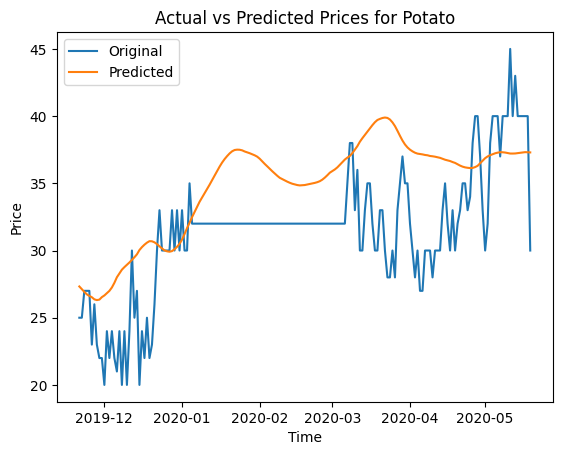

In [32]:
y_pred_col1 = y_pred[:,0]
y_test_col1 = y_test[:,0]
df_pred = pd.DataFrame({'Predicted': y_pred_col1, 'Original': y_test_col1})
results_df1 = pd.DataFrame({'Date': df.index[train_size+time_steps:], 'Original': y_test[:, 0], 'Predicted': y_pred[:, 0]})

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_col1, y_pred_col1))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_col1, y_pred_col1)))

# Plot the predicted and actual values
plt.plot(results_df1['Date'], results_df1['Original'], label='Original')
plt.plot(results_df1['Date'], results_df1['Predicted'], label='Predicted')
plt.title(f"Actual vs Predicted Prices for {df.columns[0]}")
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()

### Predicting Onion Prices

MAE:  10.679675444713613
RMSE:  12.603589882224476


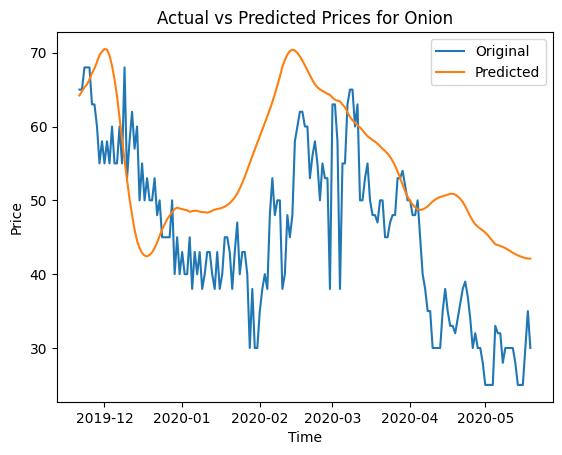

In [33]:
y_pred_col2 = y_pred[:,1]
y_test_col2 = y_test[:,1]
df_pred = pd.DataFrame({'Predicted': y_pred_col2, 'Original': y_test_col2})
results_df2 = pd.DataFrame({'Date': df.index[train_size+time_steps:], 'Original': y_test[:, 1], 'Predicted': y_pred[:, 1]})

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_col2, y_pred_col2))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_col2, y_pred_col2)))

# Plot the predicted and actual values
plt.plot(results_df2['Date'], results_df2['Original'], label='Original')
plt.plot(results_df2['Date'], results_df2['Predicted'], label='Predicted')
plt.title(f"Actual vs Predicted Prices for {df.columns[1]}")
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()

### Predicting Peas Prices

MAE:  52.69507847569924
RMSE:  61.91373130977962


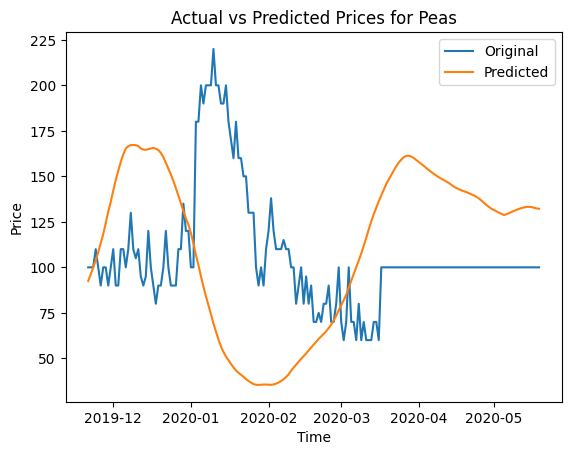

In [34]:
y_pred_col3 = y_pred[:,2]
y_test_col3 = y_test[:,2]
df_pred = pd.DataFrame({'Predicted': y_pred_col3, 'Original': y_test_col3})
results_df3 = pd.DataFrame({'Date': df.index[train_size+time_steps:], 'Original': y_test[:, 2], 'Predicted': y_pred[:, 2]})

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_col3, y_pred_col3))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_col3, y_pred_col3)))

# Plot the predicted and actual values
plt.plot(results_df3['Date'], results_df3['Original'], label='Original')
plt.plot(results_df3['Date'], results_df3['Predicted'], label='Predicted')
plt.title(f"Actual vs Predicted Prices for {df.columns[2]}")
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()

### Predicting Tomato Prices

MAE:  44.090183405586366
RMSE:  52.50773454240208


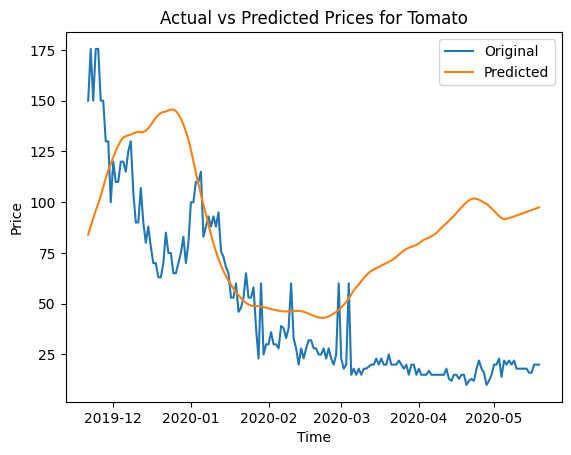

In [35]:
y_pred_col4 = y_pred[:,3]
y_test_col4 = y_test[:,3]
df_pred = pd.DataFrame({'Predicted': y_pred_col4, 'Original': y_test_col4})
results_df4 = pd.DataFrame({'Date': df.index[train_size+time_steps:], 'Original': y_test[:, 3], 'Predicted': y_pred[:, 3]})

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_col4, y_pred_col4))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_col4, y_pred_col4)))

# Plot the predicted and actual values
plt.plot(results_df4['Date'], results_df4['Original'], label='Original')
plt.plot(results_df4['Date'], results_df4['Predicted'], label='Predicted')
plt.title(f"Actual vs Predicted Prices for {df.columns[3]}")
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()

### Predicting Carrot Prices

MAE:  30.274457857753692
RMSE:  33.43682996342682


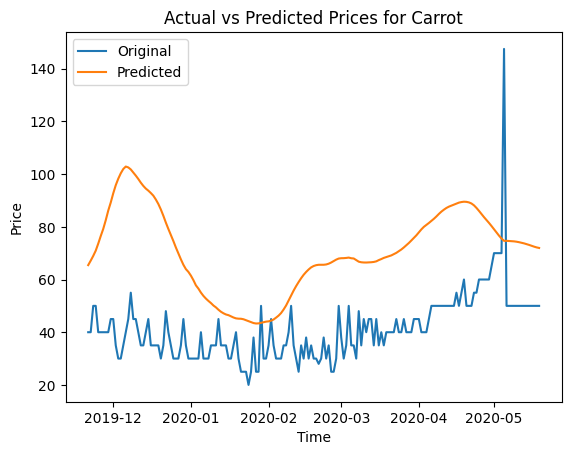

In [36]:
y_pred_col5 = y_pred[:,4]
y_test_col5 = y_test[:,4]
df_pred = pd.DataFrame({'Predicted': y_pred_col5, 'Original': y_test_col5})
results_df5 = pd.DataFrame({'Date': df.index[train_size+time_steps:], 'Original': y_test[:, 4], 'Predicted': y_pred[:, 4]})

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_col5, y_pred_col5))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_col5, y_pred_col5)))

# Plot the predicted and actual values
plt.plot(results_df5['Date'], results_df5['Original'], label='Original')
plt.plot(results_df5['Date'], results_df5['Predicted'], label='Predicted')
plt.title(f"Actual vs Predicted Prices for {df.columns[4]}")
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()

### Predicting Garlic Prices

MAE:  49.173483537705565
RMSE:  62.847919279193455


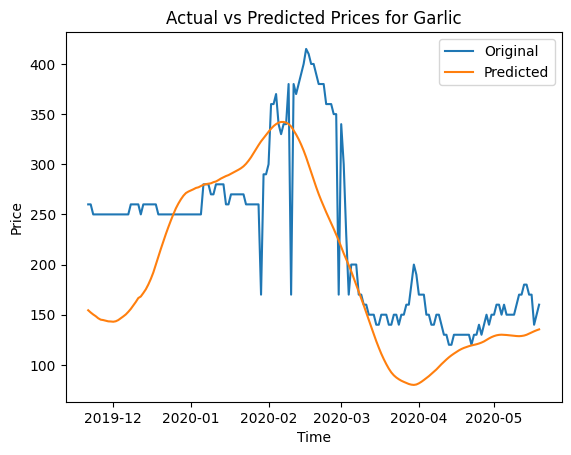

In [37]:
y_pred_col6 = y_pred[:,5]
y_test_col6 = y_test[:,5]
df_pred = pd.DataFrame({'Predicted': y_pred_col5, 'Original': y_test_col5})
results_df6 = pd.DataFrame({'Date': df.index[train_size+time_steps:], 'Original': y_test[:, 5], 'Predicted': y_pred[:, 5]})

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_col6, y_pred_col6))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_col6, y_pred_col6)))

# Plot the results
plt.plot(results_df6['Date'], results_df6['Original'], label='Original')
plt.plot(results_df6['Date'], results_df6['Predicted'], label='Predicted')
plt.title(f"Actual vs Predicted Prices for {df.columns[5]}")
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()

### Predicting Ginger Prices

MAE:  57.82591719653725
RMSE:  67.24030963457346


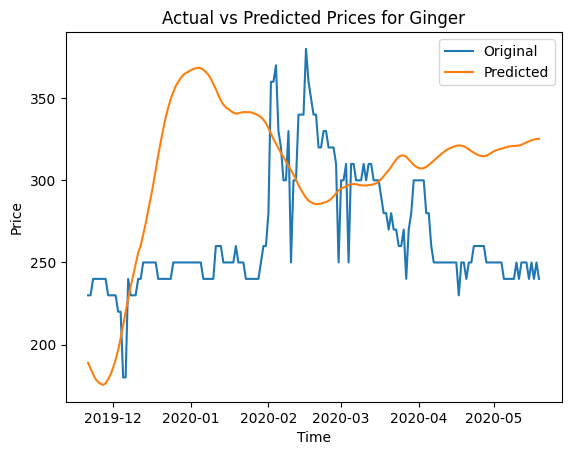

In [38]:
y_pred_col7 = y_pred[:,6]
y_test_col7 = y_test[:,6]
df_pred = pd.DataFrame({'Predicted': y_pred_col7, 'Original': y_test_col7})
results_df7 = pd.DataFrame({'Date': df.index[train_size+time_steps:], 'Original': y_test[:, 6], 'Predicted': y_pred[:, 6]})

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_col7, y_pred_col7))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_col7, y_pred_col7)))

# Plot the results
plt.plot(results_df7['Date'], results_df7['Original'], label='Original')
plt.plot(results_df7['Date'], results_df7['Predicted'], label='Predicted')
plt.title(f"Actual vs Predicted Prices for {df.columns[6]}")
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()

### Predicting Green Chilli Prices

MAE:  54.960128615574284
RMSE:  67.78143528615874


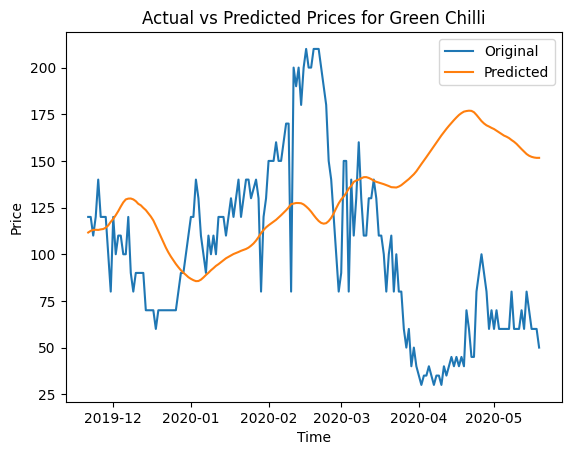

In [39]:
y_pred_col8 = y_pred[:,7]
y_test_col8 = y_test[:,7]
df_pred = pd.DataFrame({'Predicted': y_pred_col8, 'Original': y_test_col8})
results_df8 = pd.DataFrame({'Date': df.index[train_size+time_steps:], 'Original': y_test[:, 7], 'Predicted': y_pred[:, 7]})

# Calculate mean absolute error (MAE)
print("MAE: ",mean_absolute_error(y_test_col8, y_pred_col8))

# Calculate root mean squared error (RMSE)
print("RMSE: ",math.sqrt(mean_squared_error(y_test_col8, y_pred_col8)))

# Plot the results
plt.plot(results_df8['Date'], results_df8['Original'], label='Original')
plt.plot(results_df8['Date'], results_df8['Predicted'], label='Predicted')
plt.title(f"Actual vs Predicted Prices for {df.columns[7]}")
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()

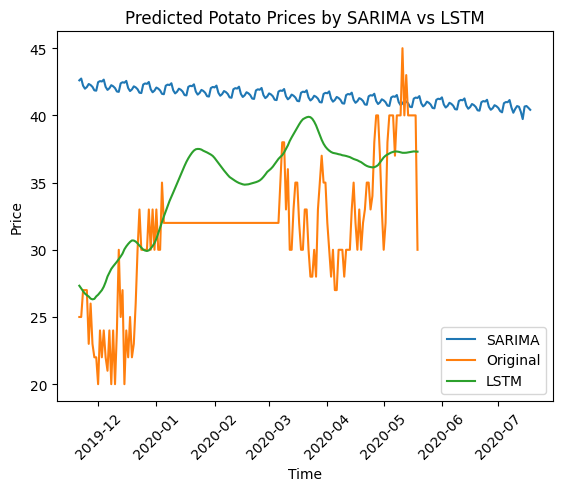

In [54]:
# Plot the results
plt.plot(date,y_pred_potato, label='SARIMA')
plt.plot(results_df1['Date'], results_df1['Original'], label='Original')
plt.plot(results_df1['Date'], results_df1['Predicted'], label='LSTM')
plt.title("Predicted Potato Prices by SARIMA vs LSTM")
plt.xlabel('Time')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.legend()
plt.show()

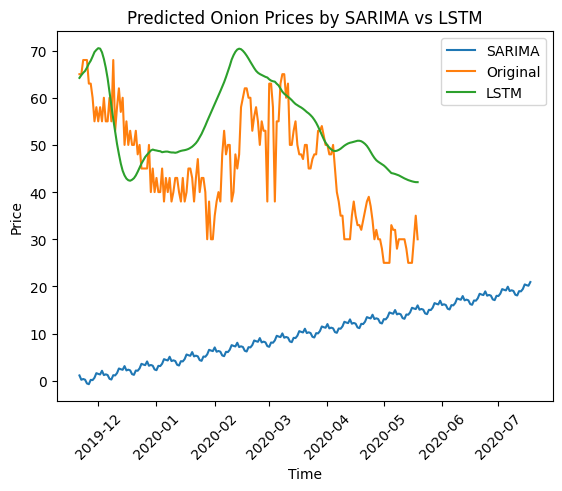

In [55]:
# Plot the results
plt.plot(date ,y_pred_onion, label='SARIMA')
plt.plot(results_df2['Date'], results_df2['Original'], label='Original')
plt.plot(results_df2['Date'], results_df2['Predicted'], label='LSTM')
plt.title("Predicted Onion Prices by SARIMA vs LSTM")
plt.xlabel('Time')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.legend()
plt.show()

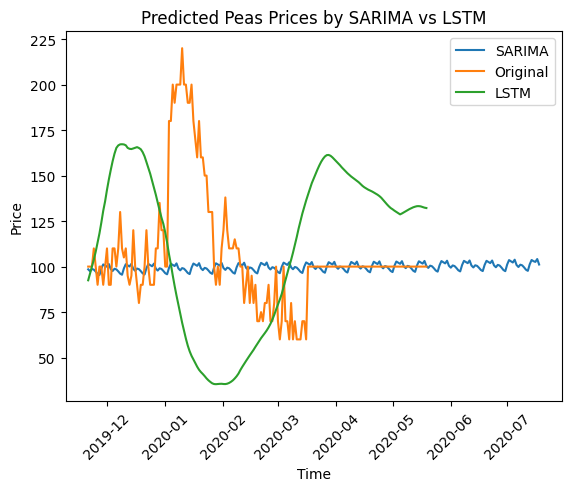

In [56]:
# Plot the results
plt.plot(date ,y_pred_peas, label='SARIMA')
plt.plot(results_df3['Date'], results_df3['Original'], label='Original')
plt.plot(results_df3['Date'], results_df3['Predicted'], label='LSTM')
plt.title("Predicted Peas Prices by SARIMA vs LSTM")
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.xticks(rotation=45)
plt.show()

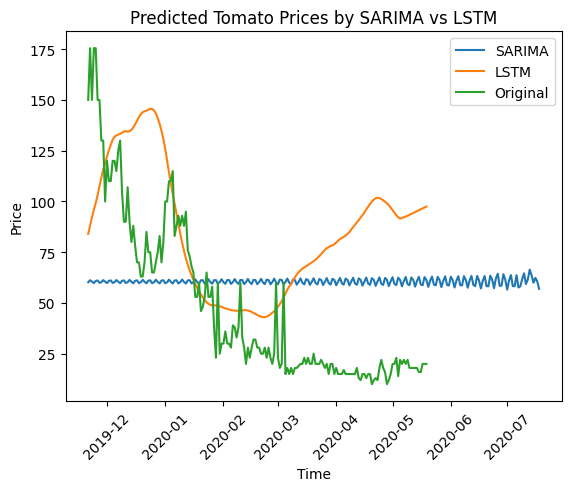

In [57]:
# Plot the results
plt.plot(date ,y_pred_tomato, label='SARIMA')
plt.plot(results_df4['Date'], results_df4['Predicted'], label='LSTM')
plt.plot(results_df4['Date'], results_df4['Original'], label='Original')
plt.title("Predicted Tomato Prices by SARIMA vs LSTM")
plt.xlabel('Time')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.legend()
plt.show()

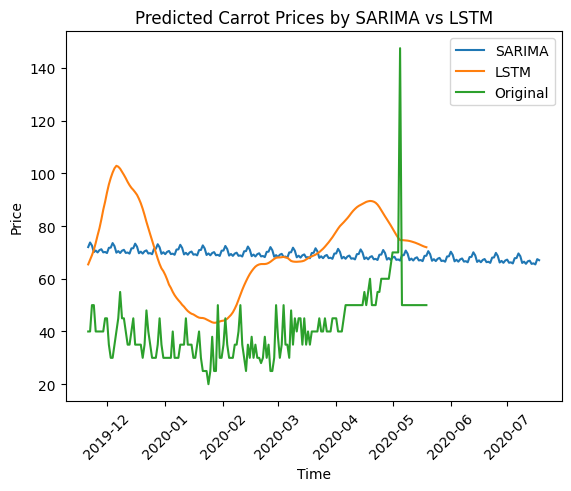

In [58]:
# Plot the results
plt.plot(date ,y_pred_carrot, label='SARIMA')
plt.plot(results_df5['Date'], results_df5['Predicted'], label='LSTM')
plt.plot(results_df5['Date'], results_df5['Original'], label='Original')
plt.title("Predicted Carrot Prices by SARIMA vs LSTM")
plt.xlabel('Time')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.legend()
plt.show()

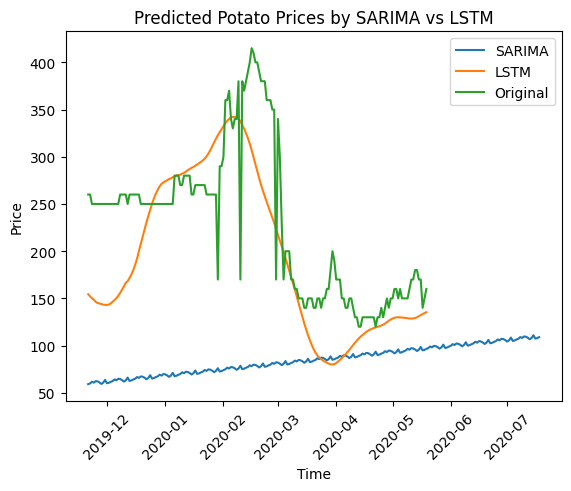

In [59]:
# Plot the results
plt.plot(date ,y_pred_garlic, label='SARIMA')
plt.plot(results_df6['Date'], results_df6['Predicted'], label='LSTM')
plt.plot(results_df6['Date'], results_df6['Original'], label='Original')
plt.title("Predicted Garlic Prices by SARIMA vs LSTM")
plt.xlabel('Time')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.legend()
plt.show()

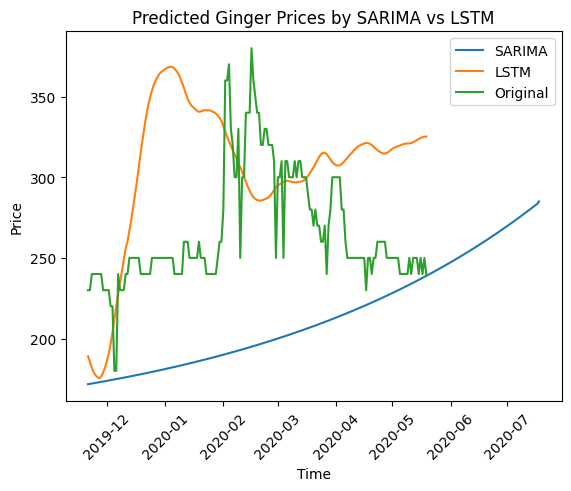

In [60]:
# Plot the results
plt.plot(date ,y_pred_ginger, label='SARIMA')
plt.plot(results_df7['Date'], results_df7['Predicted'], label='LSTM')
plt.plot(results_df7['Date'], results_df7['Original'], label='Original')
plt.title("Predicted Ginger Prices by SARIMA vs LSTM")
plt.xlabel('Time')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.legend()
plt.show()

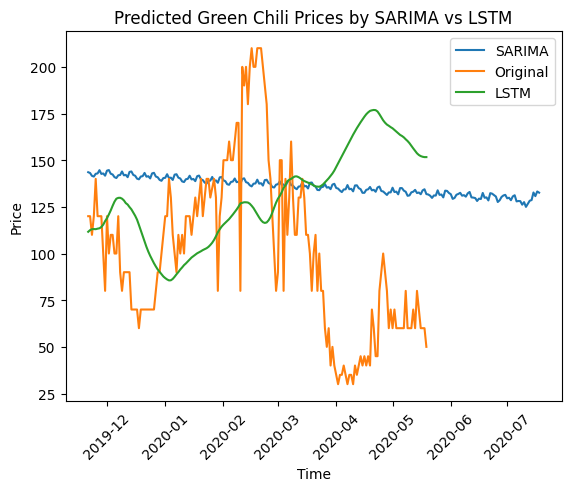

In [61]:
# Plot the results
plt.plot(date ,y_pred_chili, label='SARIMA')
plt.plot(results_df8['Date'], results_df8['Original'], label='Original')
plt.plot(results_df8['Date'], results_df8['Predicted'], label='LSTM')
plt.title("Predicted Green Chili Prices by SARIMA vs LSTM")
plt.xlabel('Time')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.legend()
plt.show()